In [1]:
# Ensure yfinance and lxml (for pd.read_html) are available in Colab
%pip install -q yfinance lxml

In [2]:
# Configure project folders (use local repo folder if cloned; otherwise mount Google Drive)
import json
import hashlib
import platform
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

if Path('data/data_provenance.json').exists():
    BASE_DIR = Path('.')
else:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_path = Path('/content/drive/MyDrive/IIT/CRM-&-CM/CWK1')
        BASE_DIR = drive_path if drive_path.exists() else Path('.')
    except ImportError:
        BASE_DIR = Path('.')

DATA_DIR = BASE_DIR / 'data'
OUTPUT_DIR = BASE_DIR / 'outputs'
FIG_DIR = BASE_DIR / 'figures'

for folder in [DATA_DIR, OUTPUT_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
BENCHMARK = '^GSPC'
START_DATE = '2021-01-01'
END_DATE = '2025-01-01'   # End date is exclusive per CWK1 specification
USE_CACHE_FIRST = True    # Reuse saved snapshots for reproducibility

# Record Python and installed package versions
packages = ['pandas', 'numpy', 'yfinance', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']
version_rows = [{'Package': 'python', 'Version': platform.python_version()}]
for pkg in packages:
    try:
        version_rows.append({'Package': pkg, 'Version': version(pkg)})
    except PackageNotFoundError:
        version_rows.append({'Package': pkg, 'Version': 'not installed'})

versions_df = pd.DataFrame(version_rows)
versions_df.to_csv(OUTPUT_DIR / 'package_versions.csv', index=False)
display(versions_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Package,Version
0,python,3.13.18
1,pandas,2.2.3
2,numpy,2.4.6
3,yfinance,0.2.66
4,scipy,1.16.3
5,scikit-learn,1.6.1
6,matplotlib,3.10.0
7,seaborn,0.13.2


In [3]:
# Task 1.1: Extract S&P 500 constituents from Wikipedia (or load cached snapshot)
TICKERS_PATH = DATA_DIR / 'sp500_tickers.csv'
PROVENANCE_PATH = DATA_DIR / 'data_provenance.json'

if USE_CACHE_FIRST and TICKERS_PATH.exists():
    sp500_df = pd.read_csv(TICKERS_PATH)
    print('Loaded cached S&P 500 ticker list:', TICKERS_PATH.name)
else:
    # User-Agent avoids HTTP 403 blocking from Wikipedia
    tables = pd.read_html(WIKI_URL, storage_options={'User-Agent': 'Mozilla/5.0'})
    sp500_df = tables[0].copy()
    sp500_df['Symbol'] = sp500_df['Symbol'].astype(str).str.strip()
    sp500_df['Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)

    keep_cols = [c for c in ['Symbol', 'Ticker', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Date added']
                 if c in sp500_df.columns]
    sp500_df = sp500_df[keep_cols].copy()
    sp500_df.to_csv(TICKERS_PATH, index=False)
    print('Downloaded and saved S&P 500 ticker list:', TICKERS_PATH.name)

tickers = sp500_df['Ticker'].tolist()
print('Total tickers extracted:', len(tickers))
print('Duplicate tickers:', sp500_df['Ticker'].duplicated().sum())
display(sp500_df.head(10))

Loaded cached S&P 500 ticker list: sp500_tickers.csv
Total tickers extracted: 503
Duplicate tickers: 0


,Symbol,Ticker,Security,GICS Sector,GICS Sub-Industry,Date added
0,MMM,MMM,3M,Industrials,Industrial Conglomerates,1957-03-04
1,AOS,AOS,A. O. Smith,Industrials,Building Products,2017-07-26
2,ABT,ABT,Abbott Laboratories,Health Care,Health Care Equipment,1957-03-04
3,ABBV,ABBV,AbbVie,Health Care,Biotechnology,2012-12-31
4,ACN,ACN,Accenture,Information Technology,IT Consulting & Other Services,2011-07-06
5,ADBE,ADBE,Adobe Inc.,Information Technology,Application Software,1997-05-05
6,AMD,AMD,Advanced Micro Devices,Information Technology,Semiconductors,2017-03-20
7,AES,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,1998-10-02
8,AFL,AFL,Aflac,Financials,Life & Health Insurance,1999-05-28
9,A,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2000-06-05


In [4]:
# Helper to standardize dates without silently dropping duplicates or filling gaps
def clean_date_index(frame, start_date, end_date):
    df = frame.copy()
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    df.index = df.index.normalize()
    df.index.name = 'Date'
    df = df.sort_index()
    return df.loc[(df.index >= pd.Timestamp(start_date)) & (df.index < pd.Timestamp(end_date))].copy()

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

SNAPSHOT_FILES = {
    'close': DATA_DIR / 'daily_close.csv',
    'adj_close': DATA_DIR / 'daily_adj_close.csv',
    'volume': DATA_DIR / 'daily_volume.csv',
    'splits': DATA_DIR / 'daily_splits.csv',
    'dividends': DATA_DIR / 'daily_dividends.csv',
    'benchmark': DATA_DIR / 'benchmark_gspc.csv',
}

cache_ready = USE_CACHE_FIRST and PROVENANCE_PATH.exists() and all(p.exists() for p in SNAPSHOT_FILES.values())

if cache_ready:
    provenance = json.loads(PROVENANCE_PATH.read_text())
    # Verify file integrity against recorded SHA-256 hashes
    for name, path in SNAPSHOT_FILES.items():
        if provenance['sha256'].get(path.name) != sha256_file(path):
            raise ValueError(f'Hash mismatch for cached file: {path.name}')
    close_df = pd.read_csv(SNAPSHOT_FILES['close'], index_col='Date', parse_dates=['Date'])
    adj_close_df = pd.read_csv(SNAPSHOT_FILES['adj_close'], index_col='Date', parse_dates=['Date'])
    volume_df = pd.read_csv(SNAPSHOT_FILES['volume'], index_col='Date', parse_dates=['Date'])
    splits_df = pd.read_csv(SNAPSHOT_FILES['splits'], index_col='Date', parse_dates=['Date'])
    dividends_df = pd.read_csv(SNAPSHOT_FILES['dividends'], index_col='Date', parse_dates=['Date'])
    bench_df = pd.read_csv(SNAPSHOT_FILES['benchmark'], index_col='Date', parse_dates=['Date'])
    print('Loaded and verified cached market snapshots from:', provenance['retrieval_date_utc'])
else:
    print('Downloading daily data for S&P 500 shares via yfinance (takes ~30-60s)...')
    raw_shares = yf.download(
        tickers,
        start=START_DATE,
        end=END_DATE,
        interval='1d',
        auto_adjust=False,
        actions=True,
        progress=False
    )
    if raw_shares.empty:
        raise RuntimeError('No share data downloaded from yfinance.')

    top_fields = set(raw_shares.columns.get_level_values(0))
    close_df = clean_date_index(raw_shares['Close'].reindex(columns=tickers), START_DATE, END_DATE)
    adj_close_df = clean_date_index(raw_shares['Adj Close'].reindex(columns=tickers), START_DATE, END_DATE)
    volume_df = clean_date_index(raw_shares['Volume'].reindex(columns=tickers), START_DATE, END_DATE)

    if 'Stock Splits' in top_fields:
        splits_df = clean_date_index(raw_shares['Stock Splits'].reindex(columns=tickers), START_DATE, END_DATE)
    else:
        splits_df = pd.DataFrame(0.0, index=close_df.index, columns=tickers)

    if 'Dividends' in top_fields:
        dividends_df = clean_date_index(raw_shares['Dividends'].reindex(columns=tickers), START_DATE, END_DATE)
    else:
        dividends_df = pd.DataFrame(0.0, index=close_df.index, columns=tickers)

    # Download S&P 500 benchmark (^GSPC) on the same window
    raw_bench = yf.download(
        BENCHMARK,
        start=START_DATE,
        end=END_DATE,
        interval='1d',
        auto_adjust=False,
        progress=False
    )
    if raw_bench.empty:
        raise RuntimeError('No benchmark (^GSPC) data downloaded from yfinance.')
    if isinstance(raw_bench.columns, pd.MultiIndex):
        raw_bench.columns = raw_bench.columns.get_level_values(0)
    bench_df = clean_date_index(raw_bench[['Close', 'Adj Close', 'Volume']], START_DATE, END_DATE)

    # Save snapshots to Drive
    close_df.to_csv(SNAPSHOT_FILES['close'], index_label='Date')
    adj_close_df.to_csv(SNAPSHOT_FILES['adj_close'], index_label='Date')
    volume_df.to_csv(SNAPSHOT_FILES['volume'], index_label='Date')
    splits_df.to_csv(SNAPSHOT_FILES['splits'], index_label='Date')
    dividends_df.to_csv(SNAPSHOT_FILES['dividends'], index_label='Date')
    bench_df.to_csv(SNAPSHOT_FILES['benchmark'], index_label='Date')

    # Save provenance record with retrieval date and SHA-256 hashes
    all_files = [TICKERS_PATH] + list(SNAPSHOT_FILES.values())
    provenance = {
        'retrieval_date_utc': datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC'),
        'wiki_url': WIKI_URL,
        'market_data_source': f'Yahoo Finance via yfinance {yf.__version__}',
        'benchmark': BENCHMARK,
        'start_date': START_DATE,
        'end_date_exclusive': END_DATE,
        'auto_adjust': False,
        'tickers_extracted': len(tickers),
        'sha256': {p.name: sha256_file(p) for p in all_files}
    }
    PROVENANCE_PATH.write_text(json.dumps(provenance, indent=2))
    print('Saved fresh snapshots and provenance record.')

print('Retrieval timestamp:', provenance['retrieval_date_utc'])
print('Shares Close shape:', close_df.shape, '| Date range:', close_df.index.min().date(), 'to', close_df.index.max().date())
print('Benchmark shape:   ', bench_df.shape, '| Date range:', bench_df.index.min().date(), 'to', bench_df.index.max().date())

Loaded and verified cached market snapshots from: 2026-11-22 17:52:57 UTC
Retrieval timestamp: 2026-11-22 17:52:57 UTC
Shares Close shape: (1005, 503) | Date range: 2021-01-04 to 2024-12-31
Benchmark shape:    (1005, 3) | Date range: 2021-01-04 to 2024-12-31


In [5]:
# Task 1.2: Diagnostic checks on raw daily share and benchmark data
print('--- 1. Duplicate Date Checks ---')
print('Share Close duplicate dates:    ', close_df.index.has_duplicates)
print('Share Adj Close duplicate dates:', adj_close_df.index.has_duplicates)
print('Share Volume duplicate dates:   ', volume_df.index.has_duplicates)
print('Benchmark duplicate dates:      ', bench_df.index.has_duplicates)

print('\n--- 2. Trading Calendar Alignment vs ^GSPC ---')
extra_share_dates = close_df.index.difference(bench_df.index)
missing_share_dates = bench_df.index.difference(close_df.index)
print('Benchmark trading dates:', len(bench_df))
print('Dates in shares not in ^GSPC:', len(extra_share_dates))
print('Dates in ^GSPC not in shares:', len(missing_share_dates))
print('Benchmark missing values:', bench_df.isna().sum().to_dict())
print('Benchmark nonpositive Close/Adj Close:', int((bench_df['Close'] <= 0).sum()), '/', int((bench_df['Adj Close'] <= 0).sum()))

# Align share tables onto the benchmark trading calendar (no filling)
close_aligned = close_df.reindex(bench_df.index)
adj_aligned = adj_close_df.reindex(bench_df.index)
vol_aligned = volume_df.reindex(bench_df.index)
splits_aligned = splits_df.reindex(bench_df.index)
divs_aligned = dividends_df.reindex(bench_df.index)

# Build per-ticker quality diagnostic table
last_60_dates = bench_df.index[-60:]
diag_rows = []
for t in tickers:
    c = close_aligned[t]
    a = adj_aligned[t]
    v = vol_aligned[t]
    sp = splits_aligned[t]
    dv = divs_aligned[t]

    diag_rows.append({
        'Ticker': t,
        'Valid_Close_Days': int(c.notna().sum()),
        'Missing_Close': int(c.isna().sum()),
        'Missing_AdjClose': int(a.isna().sum()),
        'Missing_Volume': int(v.isna().sum()),
        'NonPos_Close': int((c <= 0).sum()),
        'NonPos_AdjClose': int((a <= 0).sum()),
        'Neg_Volume': int((v < 0).sum()),
        'Zero_Volume': int((v == 0).sum()),
        'First_Valid_Date': c.first_valid_index().date() if c.notna().any() else None,
        'Last_Valid_Date': c.last_valid_index().date() if c.notna().any() else None,
        'Split_Events_All': int((sp > 0).sum()),
        'Split_Events_Last60': int((sp.loc[last_60_dates] > 0).sum()),
        'Dividend_Events_All': int((dv > 0).sum()),
    })

diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv(OUTPUT_DIR / 'validation_diagnostics.csv', index=False)

total_days = len(bench_df)
print('\n--- 3. Share Completeness & Error Summary ---')
print('Total extracted tickers:                 ', len(diag_df))
print('Failed downloads (0 valid days):         ', int((diag_df['Valid_Close_Days'] == 0).sum()))
print('Full history (100% Close/Adj/Vol valid): ', int(((diag_df['Missing_Close'] == 0) &
                                                      (diag_df['Missing_AdjClose'] == 0) &
                                                      (diag_df['Missing_Volume'] == 0)).sum()))
print('Unequal/partial histories (>0 missing):  ', int(((diag_df['Valid_Close_Days'] > 0) &
                                                      ((diag_df['Missing_Close'] > 0) |
                                                       (diag_df['Missing_AdjClose'] > 0) |
                                                       (diag_df['Missing_Volume'] > 0))).sum()))
print('Tickers with nonpositive Close/AdjClose: ', int(((diag_df['NonPos_Close'] > 0) | (diag_df['NonPos_AdjClose'] > 0)).sum()))
print('Tickers with negative Volume:            ', int((diag_df['Neg_Volume'] > 0).sum()))
print('Tickers with zero Volume days:           ', int((diag_df['Zero_Volume'] > 0).sum()))

print('\n--- 4. Corporate Actions Summary (2021-2024) ---')
print('Tickers with stock splits (full window): ', int((diag_df['Split_Events_All'] > 0).sum()))
print('Tickers with splits in final 60 sessions:', int((diag_df['Split_Events_Last60'] > 0).sum()))
print('Tickers with dividends (full window):    ', int((diag_df['Dividend_Events_All'] > 0).sum()))

# Inspect all tickers that have any missing data, nonpositive prices, or volume anomalies
issues_df = diag_df[
    (diag_df['Missing_Close'] > 0) |
    (diag_df['Missing_AdjClose'] > 0) |
    (diag_df['Missing_Volume'] > 0) |
    (diag_df['NonPos_Close'] > 0) |
    (diag_df['NonPos_AdjClose'] > 0) |
    (diag_df['Neg_Volume'] > 0) |
    (diag_df['Zero_Volume'] > 0)
].sort_values('Missing_Close', ascending=False)

print(f'\nTickers flagged with any completeness or value issue ({len(issues_df)}):')
display(issues_df)

--- 1. Duplicate Date Checks ---
Share Close duplicate dates:     False
Share Adj Close duplicate dates: False
Share Volume duplicate dates:    False
Benchmark duplicate dates:       False

--- 2. Trading Calendar Alignment vs ^GSPC ---
Benchmark trading dates: 1005
Dates in shares not in ^GSPC: 0
Dates in ^GSPC not in shares: 0
Benchmark missing values: {'Close': 0, 'Adj Close': 0, 'Volume': 0}
Benchmark nonpositive Close/Adj Close: 0 / 0

--- 3. Share Completeness & Error Summary ---
Total extracted tickers:                  503
Failed downloads (0 valid days):          5
Full history (100% Close/Adj/Vol valid):  488
Unequal/partial histories (>0 missing):   10
Tickers with nonpositive Close/AdjClose:  0
Tickers with negative Volume:             0
Tickers with zero Volume days:            2

--- 4. Corporate Actions Summary (2021-2024) ---
Tickers with stock splits (full window):  53
Tickers with splits in final 60 sessions: 4
Tickers with dividends (full window):     399

Tickers fl

,Ticker,Valid_Close_Days,Missing_Close,Missing_AdjClose,Missing_Volume,NonPos_Close,NonPos_AdjClose,Neg_Volume,Zero_Volume,First_Valid_Date,Last_Valid_Date,Split_Events_All,Split_Events_Last60,Dividend_Events_All
192,FDXF,0,1005,1005,1005,0,0,0,0,None,None,0,0,0
478,VYLR,0,1005,1005,1005,0,0,0,0,None,None,0,0,0
233,HONA,0,1005,1005,1005,0,0,0,0,None,None,0,0,0
402,SNDK,0,1005,1005,1005,0,0,0,0,None,None,0,0,0
379,Q,0,1005,1005,1005,0,0,0,0,None,None,0,0,0
211,GEV,193,812,812,812,0,0,0,0,2024-03-27,2024-12-31,0,0,1
415,SOLV,194,811,811,811,0,0,0,0,2024-03-26,2024-12-31,0,0,0
385,RDDT,197,808,808,808,0,0,0,0,2024-03-21,2024-12-31,0,0,0
466,VLTO,313,692,692,692,0,0,0,0,2023-10-04,2024-12-31,0,0,5
210,GEHC,513,492,492,492,0,0,0,0,2022-12-15,2024-12-31,0,0,7


In [6]:
# Task 1.2 / 1.4.3: Inspect zero-volume anomalies and recent stock splits
print('--- Zero-Volume Ticker Inspection ---')
for t in ['FERG', 'SW']:
    z_mask = vol_aligned[t] == 0
    z_dates = vol_aligned.index[z_mask]
    z_last60 = int((vol_aligned.loc[last_60_dates, t] == 0).sum())
    flat_on_zero = int((close_aligned[t].diff().loc[z_dates] == 0).sum())
    print(f'{t}: {len(z_dates)} zero-volume days '
          f'({z_dates.min().date()} to {z_dates.max().date()}), '
          f'last-60 count = {z_last60}, unchanged Close on zero-vol days = {flat_on_zero}')

# Inspect the 4 shares with stock splits in the final 60 sessions
split_last60_tickers = diag_df.loc[diag_df['Split_Events_Last60'] > 0, 'Ticker'].tolist()
print('\n--- Stock Splits in Final 60 Trading Sessions ---')
print('Tickers with splits in last 60 sessions:', split_last60_tickers)

for t in split_last60_tickers:
    sp_dates = splits_aligned.loc[last_60_dates, t]
    for dt, ratio in sp_dates[sp_dates > 0].items():
        pos = bench_df.index.get_loc(dt)
        window = bench_df.index[max(0, pos - 1):min(len(bench_df), pos + 2)]
        check_tbl = pd.DataFrame({
            'Close': close_aligned.loc[window, t],
            'Adj_Close': adj_aligned.loc[window, t],
            'Volume': vol_aligned.loc[window, t],
            'Split_Ratio': splits_aligned.loc[window, t],
            'Close_x_Vol_USD': close_aligned.loc[window, t] * vol_aligned.loc[window, t]
        })
        print(f'\n{t} split on {dt.date()} (ratio {ratio}):')
        display(check_tbl)

# Check whether ^GSPC Close and Adj Close are identical (price index vs dividend-adjusted shares)
bench_diff = float((bench_df['Close'] - bench_df['Adj Close']).abs().max())
print(f'\nMax |Close - Adj Close| for ^GSPC benchmark: {bench_diff:.6f}')

--- Zero-Volume Ticker Inspection ---
FERG: 27 zero-volume days (2021-01-07 to 2021-03-05), last-60 count = 0, unchanged Close on zero-vol days = 27
SW: 424 zero-volume days (2021-01-05 to 2024-07-05), last-60 count = 0, unchanged Close on zero-vol days = 424

--- Stock Splits in Final 60 Trading Sessions ---
Tickers with splits in last 60 sessions: ['ANET', 'ETR', 'PANW', 'TSCO']

ANET split on 2024-12-04 (ratio 4.0):


,Close,Adj_Close,Volume,Split_Ratio,Close_x_Vol_USD
Date,,,,,
2024-12-03,103.614998,103.614998,7181200,0.0,7.440800e+08
2024-12-04,105.430000,105.430000,5845900,4.0,6.163332e+08
2024-12-05,106.830002,106.830002,6967000,0.0,7.442846e+08



ETR split on 2024-12-13 (ratio 2.0):


,Close,Adj_Close,Volume,Split_Ratio,Close_x_Vol_USD
Date,,,,,
2024-12-12,74.135002,70.389221,3252000,0.0,2.410870e+08
2024-12-13,74.239998,70.488914,3294500,2.0,2.445837e+08
2024-12-16,74.760002,70.982635,3607900,0.0,2.697266e+08



PANW split on 2024-12-16 (ratio 2.0):


,Close,Adj_Close,Volume,Split_Ratio,Close_x_Vol_USD
Date,,,,,
2024-12-13,196.559998,196.559998,3848800,0.0,7.565201e+08
2024-12-16,202.500000,202.500000,6087000,2.0,1.232618e+09
2024-12-17,201.240005,201.240005,5429900,0.0,1.092713e+09



TSCO split on 2024-12-20 (ratio 5.0):


,Close,Adj_Close,Volume,Split_Ratio,Close_x_Vol_USD
Date,,,,,
2024-12-19,52.806000,50.931225,7494000,0.0,3.957282e+08
2024-12-20,53.919998,52.005676,10938900,5.0,5.898255e+08
2024-12-23,53.689999,51.783840,5348600,0.0,2.871663e+08



Max |Close - Adj Close| for ^GSPC benchmark: 0.000000


In [7]:
# Task 1.2: Apply transparent daily validation rules (no forward/backward filling)
exclusion_rows = []
valid_daily_tickers = []

for _, row in diag_df.iterrows():
    t = row['Ticker']
    reasons = []
    if row['Valid_Close_Days'] == 0:
        reasons.append('Failed download (no 2021-2024 price/volume data)')
    elif (row['Missing_Close'] > 0) or (row['Missing_AdjClose'] > 0) or (row['Missing_Volume'] > 0):
        reasons.append(f"Unequal/incomplete history ({row['Valid_Close_Days']}/{total_days} valid days; first date {row['First_Valid_Date']})")
    if (row['NonPos_Close'] > 0) or (row['NonPos_AdjClose'] > 0):
        reasons.append('Nonpositive Close or Adj Close price')
    if row['Neg_Volume'] > 0:
        reasons.append(f"Negative volume ({row['Neg_Volume']} days)")
    if row['Zero_Volume'] > 0:
        reasons.append(f"Zero-volume trading days ({row['Zero_Volume']} days)")

    if reasons:
        exclusion_rows.append({
            'Ticker': t,
            'Stage': 'Task 1.2 Daily Validation',
            'Reason': '; '.join(reasons)
        })
    else:
        valid_daily_tickers.append(t)

# Subset aligned daily tables to validated full-history shares
close_valid = close_aligned[valid_daily_tickers].copy()
adj_valid = adj_aligned[valid_daily_tickers].copy()
vol_valid = vol_aligned[valid_daily_tickers].copy()

# Confirm zero missing or nonpositive values remain
assert close_valid.isna().sum().sum() == 0
assert adj_valid.isna().sum().sum() == 0
assert vol_valid.isna().sum().sum() == 0
assert (close_valid <= 0).sum().sum() == 0
assert (adj_valid <= 0).sum().sum() == 0
assert (vol_valid <= 0).sum().sum() == 0

print(f'Extracted tickers:         {len(tickers)}')
print(f'Excluded in Task 1.2:      {len(exclusion_rows)}')
print(f'Retained for Task 1.3/1.4: {len(valid_daily_tickers)}')

Extracted tickers:         503
Excluded in Task 1.2:      17
Retained for Task 1.3/1.4: 486


In [8]:
# Task 1.3: Resample daily Adjusted Close to Friday-ending weekly prices
share_weekly_raw = adj_valid.resample('W-FRI').last()
bench_weekly_raw = bench_df['Adj Close'].resample('W-FRI').last()

# Keep only complete calendar weeks inside [START_DATE, END_DATE)
# A Friday-ending week spans Monday (week_end - 4 days) through Friday (week_end)
start_ts = pd.Timestamp(START_DATE)
end_ts = pd.Timestamp(END_DATE)
week_starts = share_weekly_raw.index - pd.Timedelta(days=4)
complete_week_mask = (week_starts >= start_ts) & (share_weekly_raw.index < end_ts)

excluded_weeks = share_weekly_raw.index[~complete_week_mask]
print('Excluded incomplete boundary calendar weeks:', [str(d.date()) for d in excluded_weeks])

share_weekly_prices = share_weekly_raw.loc[complete_week_mask].copy()
bench_weekly_prices = bench_weekly_raw.loc[complete_week_mask].copy()

# Calculate simple weekly returns without filling missing values
share_weekly_returns = share_weekly_prices.pct_change(fill_method=None)
bench_weekly_returns = bench_weekly_prices.pct_change(fill_method=None)

# Drop the initial week (no preceding week exists inside the study window)
share_weekly_returns = share_weekly_returns.iloc[1:].copy()
bench_weekly_returns = bench_weekly_returns.iloc[1:].copy()

# Verify exact 7-day spacing (no multi-week jumps) and zero NaNs
assert share_weekly_returns.index.equals(bench_weekly_returns.index)
assert share_weekly_returns.index.to_series().diff().dropna().eq(pd.Timedelta(days=7)).all()
assert share_weekly_returns.isna().sum().sum() == 0
assert bench_weekly_returns.isna().sum() == 0

print(f'Complete weekly price endpoints: {len(share_weekly_prices)} '
      f'({share_weekly_prices.index.min().date()} to {share_weekly_prices.index.max().date()})')
print(f'Aligned weekly return periods:   {len(share_weekly_returns)} '
      f'({share_weekly_returns.index.min().date()} to {share_weekly_returns.index.max().date()})')

# Calculate arithmetic mean weekly return and full-period weekly beta
risk_return_rows = []
for t in valid_daily_tickers:
    paired = pd.concat(
        [share_weekly_returns[t].rename('Share'), bench_weekly_returns.rename('Market')],
        axis=1
    ).replace([np.inf, -np.inf], np.nan).dropna()

    market_var = paired['Market'].var(ddof=1)
    beta = paired['Share'].cov(paired['Market']) / market_var if market_var > 0 else np.nan
    mean_ret = paired['Share'].mean()

    risk_return_rows.append({
        'Ticker': t,
        'Aligned_Weeks': len(paired),
        'Mean_Weekly_Return': mean_ret,
        'Weekly_Beta': beta
    })

risk_return_df = pd.DataFrame(risk_return_rows)

# Independent verification on AAPL: compare Cov/Var beta against OLS regression slope
aapl_slope = np.polyfit(bench_weekly_returns.to_numpy(), share_weekly_returns['AAPL'].to_numpy(), 1)[0]
aapl_beta = risk_return_df.loc[risk_return_df['Ticker'] == 'AAPL', 'Weekly_Beta'].iloc[0]
print(f'\nIndependent Beta check (AAPL): Cov/Var = {aapl_beta:.8f} | OLS slope = {aapl_slope:.8f} | Diff = {abs(aapl_beta - aapl_slope):.2e}')

# Save aligned weekly returns for reproducibility
share_weekly_returns.to_csv(OUTPUT_DIR / 'weekly_returns_shares.csv', index_label='Week_End')
bench_weekly_returns.rename('GSPC_Weekly_Return').to_csv(OUTPUT_DIR / 'weekly_returns_benchmark.csv', index_label='Week_End')
display(risk_return_df.head(10))

Excluded incomplete boundary calendar weeks: ['2025-01-03']
Complete weekly price endpoints: 208 (2021-01-08 to 2024-12-27)
Aligned weekly return periods:   207 (2021-01-15 to 2024-12-27)

Independent Beta check (AAPL): Cov/Var = 1.17483594 | OLS slope = 1.17483594 | Diff = 8.88e-16


,Ticker,Aligned_Weeks,Mean_Weekly_Return,Weekly_Beta
0,MMM,207,0.001142,0.869078
1,AOS,207,0.001991,1.042805
2,ABT,207,0.000971,0.583543
3,ABBV,207,0.003749,0.425366
4,ACN,207,0.002376,1.143300
5,ADBE,207,0.000990,1.553525
6,AMD,207,0.003624,1.877622
7,AES,207,-0.001420,1.143912
8,AFL,207,0.005004,0.707196
9,A,207,0.001121,1.074724


In [9]:
# Task 1.4: Adapted RFM calculations using daily Close and Volume
OBSERVATION_DATE = bench_df.index[-1]   # Final common completed trading date (2024-12-31)
print('Explicit RFM observation date:', OBSERVATION_DATE.date())

rfm_rows = []
for t in valid_daily_tickers:
    c = close_valid[t]
    v = vol_valid[t]

    # Rolling mean of the preceding 20 trading sessions, excluding the day being tested
    avg_vol_20 = v.shift(1).rolling(window=20, min_periods=20).mean()
    high_vol = v > (2.0 * avg_vol_20)

    # Keep only days with a complete 20-session baseline
    valid_mask = avg_vol_20.notna()
    if int(valid_mask.sum()) < 60:
        exclusion_rows.append({
            'Ticker': t,
            'Stage': 'Task 1.4 RFM Calculation',
            'Reason': 'Insufficient valid history for 20-session baseline + 60-session window'
        })
        continue

    valid_hv = high_vol.loc[valid_mask]
    recent_hv = valid_hv.tail(60)
    recent_c = c.loc[recent_hv.index]
    recent_v = v.loc[recent_hv.index]

    assert len(recent_hv) == 60
    assert recent_hv.index[-1] == OBSERVATION_DATE

    # 1.4.1 Recency: calendar days since latest qualifying event in valid history
    event_dates = valid_hv.index[valid_hv]
    if len(event_dates) > 0:
        last_event_date = event_dates[-1]
        recency = int((OBSERVATION_DATE - last_event_date).days)
    else:
        last_event_date = pd.NaT
        recency = None   # Do not substitute zero when no event occurs

    # 1.4.2 Frequency: count of qualifying high-volume days in final 60 trading sessions
    frequency = int(recent_hv.sum())

    # 1.4.3 Monetary: sum of Close * Volume over final 60 trading sessions (USD)
    monetary = float((recent_c * recent_v).sum())

    rfm_rows.append({
        'Ticker': t,
        'Observation_Date': OBSERVATION_DATE.date(),
        'Last_HighVol_Date': last_event_date.date() if pd.notna(last_event_date) else None,
        'Recency': recency,
        'Frequency': frequency,
        'Monetary': monetary
    })

rfm_df = pd.DataFrame(rfm_rows)
rfm_df['Recency'] = rfm_df['Recency'].astype('Int64')

# Log any shares with no qualifying high-volume event across the valid study history
no_event_tickers = rfm_df.loc[rfm_df['Recency'].isna(), 'Ticker'].tolist()
print('Shares with NO qualifying high-volume event (Recency missing):', len(no_event_tickers), no_event_tickers)
for t in no_event_tickers:
    exclusion_rows.append({
        'Ticker': t,
        'Stage': 'Task 1.4.1 RFM Recency',
        'Reason': 'No qualifying high-volume event (>2x prior 20-day mean) in valid 2021-2024 history'
    })

# Combine Risk-Return, RFM, and GICS Sector metadata into one common valid share set
feature_all = (
    sp500_df[['Ticker', 'Security', 'GICS Sector', 'GICS Sub-Industry']]
    .merge(risk_return_df, on='Ticker', how='inner')
    .merge(rfm_df, on='Ticker', how='inner')
)

required_features = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
feature_df = feature_all.dropna(subset=required_features).reset_index(drop=True)

# Save full exclusion log and common valid feature table
exclusion_log_df = pd.DataFrame(exclusion_rows).drop_duplicates().reset_index(drop=True)
exclusion_log_df.to_csv(OUTPUT_DIR / 'exclusion_log.csv', index=False)
feature_df.to_csv(OUTPUT_DIR / 'task1_feature_table.csv', index=False)

print(f'\nTotal excluded tickers (all stages): {len(exclusion_log_df)}')
print(f'Final common valid share set:        {len(feature_df)} shares')
print('Zero-day Recency (event on 2024-12-31) count:', int((feature_df['Recency'] == 0).sum()))
print('Zero Frequency in last 60 sessions count:    ', int((feature_df['Frequency'] == 0).sum()))
display(exclusion_log_df)
display(feature_df.head(10))

Explicit RFM observation date: 2024-12-31
Shares with NO qualifying high-volume event (Recency missing): 0 []

Total excluded tickers (all stages): 17
Final common valid share set:        486 shares
Zero-day Recency (event on 2024-12-31) count: 0
Zero Frequency in last 60 sessions count:     10


,Ticker,Stage,Reason
0,APP,Task 1.2 Daily Validation,Unequal/incomplete history (935/1005 valid day...
1,COIN,Task 1.2 Daily Validation,Unequal/incomplete history (936/1005 valid day...
2,CEG,Task 1.2 Daily Validation,Unequal/incomplete history (742/1005 valid day...
3,EXE,Task 1.2 Daily Validation,Unequal/incomplete history (979/1005 valid day...
4,FDXF,Task 1.2 Daily Validation,Failed download (no 2021-2024 price/volume data)
5,FERG,Task 1.2 Daily Validation,Zero-volume trading days (27 days)
6,GEHC,Task 1.2 Daily Validation,Unequal/incomplete history (513/1005 valid day...
7,GEV,Task 1.2 Daily Validation,Unequal/incomplete history (193/1005 valid day...
8,HONA,Task 1.2 Daily Validation,Failed download (no 2021-2024 price/volume data)
9,Q,Task 1.2 Daily Validation,Failed download (no 2021-2024 price/volume data)


,Ticker,Security,GICS Sector,GICS Sub-Industry,Aligned_Weeks,Mean_Weekly_Return,Weekly_Beta,Observation_Date,Last_HighVol_Date,Recency,Frequency,Monetary
0,MMM,3M,Industrials,Industrial Conglomerates,207,0.001142,0.869078,2024-12-31,2024-12-20,11,4,2.599146e+10
1,AOS,A. O. Smith,Industrials,Building Products,207,0.001991,1.042805,2024-12-31,2024-12-20,11,2,4.748980e+09
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,207,0.000971,0.583543,2024-12-31,2024-12-20,11,1,3.523027e+10
3,ABBV,AbbVie,Health Care,Biotechnology,207,0.003749,0.425366,2024-12-31,2024-12-20,11,3,6.837054e+10
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,207,0.002376,1.143300,2024-12-31,2024-12-20,11,2,5.199430e+10
5,ADBE,Adobe Inc.,Information Technology,Application Software,207,0.000990,1.553525,2024-12-31,2024-12-13,18,3,1.030403e+11
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,207,0.003624,1.877622,2024-12-31,2024-12-13,18,4,3.131659e+11
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,207,-0.001420,1.143912,2024-12-31,2024-11-07,54,3,1.119578e+10
8,AFL,Aflac,Financials,Life & Health Insurance,207,0.005004,0.707196,2024-12-31,2024-12-20,11,2,1.328456e+10
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,207,0.001121,1.074724,2024-12-31,2024-12-20,11,2,1.400180e+10


In [10]:
# Task 1.5: Worked RFM example for one share + feature summary statistics
# Pick a well-known share with at least 1 qualifying high-volume day in the last 60 sessions
example_ticker = None
for cand in ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'META', 'JPM']:
    row_c = feature_df.loc[feature_df['Ticker'] == cand]
    if not row_c.empty and int(row_c['Frequency'].iloc[0]) >= 1:
        example_ticker = cand
        break
if example_ticker is None:
    example_ticker = feature_df.loc[feature_df['Frequency'] >= 1, 'Ticker'].iloc[0]

c_ex = close_valid[example_ticker]
v_ex = vol_valid[example_ticker]
avg20_ex = v_ex.shift(1).rolling(window=20, min_periods=20).mean()

worked_df = pd.DataFrame({
    'Close_USD': c_ex,
    'Volume': v_ex,
    'Prior_20D_Avg_Vol': avg20_ex,
    'Threshold_2x': 2.0 * avg20_ex,
    'Qualifies_HighVol': v_ex > (2.0 * avg20_ex),
    'Daily_Traded_Value_USD': c_ex * v_ex
})

valid_worked = worked_df.loc[worked_df['Prior_20D_Avg_Vol'].notna()]
last60_worked = valid_worked.tail(60)
qualifying_last60 = last60_worked.loc[last60_worked['Qualifies_HighVol']]

print(f'=== Worked RFM Example: {example_ticker} ===')
print(f'Observation date:          {OBSERVATION_DATE.date()}')
print(f'60-session window:         {last60_worked.index.min().date()} to {last60_worked.index.max().date()} ({len(last60_worked)} sessions)')
print(f'Latest qualifying event:   {valid_worked.index[valid_worked["Qualifies_HighVol"]][-1].date()}')
print(f'Recency (calendar days):   {int(feature_df.loc[feature_df["Ticker"] == example_ticker, "Recency"].iloc[0])}')
print(f'Frequency (last 60 days):  {int(qualifying_last60.shape[0])}')
print(f'Monetary (last 60 days):   ${last60_worked["Daily_Traded_Value_USD"].sum():,.2f} '
      f'(${last60_worked["Daily_Traded_Value_USD"].sum()/1e9:.2f}B)')

print('\nQualifying high-volume day(s) in the final 60 sessions:')
display(qualifying_last60)

print('\nLast 5 trading sessions of the 60-day Monetary window:')
display(last60_worked[['Close_USD', 'Volume', 'Daily_Traded_Value_USD']].tail(5))

# Save full 60-session worked table for report verification
last60_worked.to_csv(OUTPUT_DIR / f'worked_example_{example_ticker}_60d.csv', index_label='Date')

# Summary statistics table for all 5 features on the common valid share set
summary_cols = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
summary_tbl = feature_df[summary_cols].astype(float).describe().T
summary_tbl['skew'] = feature_df[summary_cols].astype(float).skew()
summary_tbl = summary_tbl[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skew']]
summary_tbl.to_csv(OUTPUT_DIR / 'task1_feature_summary.csv')

print('\n=== Feature Summary Statistics (Common Valid Share Set) ===')
display(summary_tbl.round(4))

print('\nTop 5 & Bottom 5 Shares by Weekly Beta:')
display(feature_df.nlargest(5, 'Weekly_Beta')[['Ticker', 'GICS Sector', 'Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']])
display(feature_df.nsmallest(5, 'Weekly_Beta')[['Ticker', 'GICS Sector', 'Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']])

print('\nTop 5 Shares by Monetary Value (60-session Traded Value in USD):')
display(feature_df.nlargest(5, 'Monetary')[['Ticker', 'GICS Sector', 'Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']])

=== Worked RFM Example: AAPL ===
Observation date:          2024-12-31
60-session window:         2024-10-07 to 2024-12-31 (60 sessions)
Latest qualifying event:   2024-12-20
Recency (calendar days):   11
Frequency (last 60 days):  2
Monetary (last 60 days):   $623,303,377,706.58 ($623.30B)

Qualifying high-volume day(s) in the final 60 sessions:


,Close_USD,Volume,Prior_20D_Avg_Vol,Threshold_2x,Qualifies_HighVol,Daily_Traded_Value_USD
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10



Last 5 trading sessions of the 60-day Monetary window:


,Close_USD,Volume,Daily_Traded_Value_USD
Date,,,
2024-12-24,258.200012,23234700,5.999200e+09
2024-12-26,259.019989,27237100,7.054953e+09
2024-12-27,255.589996,42355300,1.082559e+10
2024-12-30,252.199997,35557500,8.967601e+09
2024-12-31,250.419998,39480700,9.886757e+09



=== Feature Summary Statistics (Common Valid Share Set) ===


,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,486.0,2.900000e-03,2.700000e-03,-4.500000e-03,1.200000e-03,2.600000e-03,4.200000e-03,1.780000e-02,0.8675
Weekly_Beta,486.0,9.737000e-01,4.073000e-01,5.550000e-02,6.666000e-01,9.506000e-01,1.179500e+00,3.778600e+00,1.1036
Recency,486.0,2.040740e+01,2.134240e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02,3.6458
Frequency,486.0,2.989700e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.4247
Monetary,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12,11.6838



Top 5 & Bottom 5 Shares by Weekly Beta:


,Ticker,GICS Sector,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
85,CVNA,Consumer Discretionary,0.010964,3.778560,36,3,3.836519e+10
65,XYZ,Financials,-0.001554,2.504520,49,5,4.052406e+10
114,COHR,Information Technology,0.003887,2.139305,11,3,1.443629e+10
332,NVDA,Information Technology,0.013624,2.125953,222,0,1.825337e+12
435,TWLO,Information Technology,-0.002161,2.073379,11,4,1.520773e+10


,Ticker,GICS Sector,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
207,GIS,Consumer Staples,0.001522,0.055453,11,2,1.546400e+10
399,SJM,Consumer Staples,0.000804,0.175579,35,4,7.557593e+09
298,MRK,Health Care,0.002132,0.198287,11,2,6.803267e+10
71,BMY,Health Care,0.000774,0.225014,11,3,3.561004e+10
268,KHC,Consumer Staples,0.000855,0.227169,46,2,1.795750e+10



Top 5 Shares by Monetary Value (60-session Traded Value in USD):


,Ticker,GICS Sector,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
422,TSLA,Consumer Discretionary,0.005275,2.045761,50,5,1.847697e+12
332,NVDA,Information Technology,0.013624,2.125953,222,0,1.825337e+12
38,AAPL,Information Technology,0.003930,1.174836,11,2,6.233034e+11
305,MSFT,Information Technology,0.003982,1.128576,11,2,5.348982e+11
22,AMZN,Consumer Discretionary,0.002681,1.386667,11,5,4.681770e+11


Common share count across both feature matrices: 486

Monetary skewness: raw = 11.6838 -> log1p = 1.0791
Recency skewness (diagnostic check only): raw = 3.6458 -> log1p = 1.5832


,Feature,Mean,Median,Skew_Raw,IQR_Outliers,Pct_Outliers
0,Mean_Weekly_Return,2.900000e-03,2.600000e-03,0.8675,15,3.0864
1,Weekly_Beta,9.737000e-01,9.506000e-01,1.1036,10,2.0576
2,Recency,2.040740e+01,1.100000e+01,3.6458,115,23.6626
3,Frequency,2.989700e+00,3.000000e+00,0.4247,2,0.4115
4,Monetary,3.940419e+10,1.668382e+10,11.6838,45,9.2593



Risk-Return scaled check -> mean: {'Mean_Weekly_Return': -0.0, 'Weekly_Beta': 0.0} | std: {'Mean_Weekly_Return': 1.0, 'Weekly_Beta': 1.0}
RFM scaled check         -> mean: {'Recency': -0.0, 'Frequency': -0.0, 'LogMonetary': -0.0} | std: {'Recency': 1.0, 'Frequency': 1.0, 'LogMonetary': 1.0}


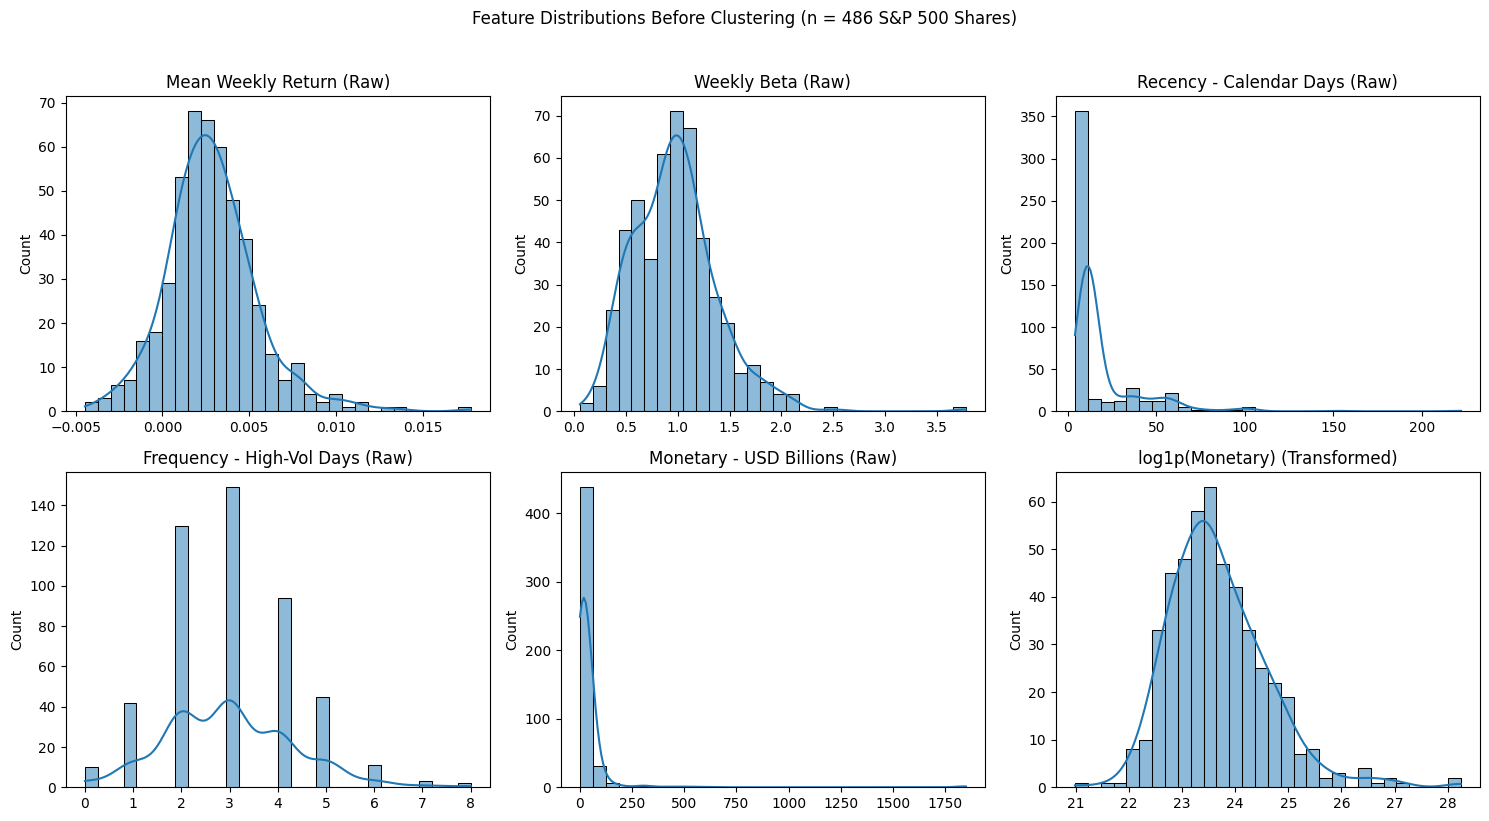

In [11]:
# Task 2.1: Prepare separate Risk-Return and RFM feature matrices on common 486 shares
from sklearn.preprocessing import StandardScaler

rr_cols = ['Mean_Weekly_Return', 'Weekly_Beta']
rfm_cols = ['Recency', 'Frequency', 'Monetary']

# Create two separate feature DataFrames indexed by Ticker
X_rr_raw = feature_df.set_index('Ticker')[rr_cols].astype(float).copy()
X_rfm_raw = feature_df.set_index('Ticker')[rfm_cols].astype(float).copy()

# Verify both matrices contain the exact same common share set
assert X_rr_raw.index.equals(X_rfm_raw.index)
print('Common share count across both feature matrices:', len(X_rr_raw))

# Inspect skewness and IQR outliers across all five raw features
outlier_rows = []
for col in rr_cols + rfm_cols:
    s = feature_df[col].astype(float)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low_f, high_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < low_f) | (s > high_f)).sum())
    outlier_rows.append({
        'Feature': col,
        'Mean': s.mean(),
        'Median': s.median(),
        'Skew_Raw': s.skew(),
        'IQR_Outliers': n_out,
        'Pct_Outliers': 100 * n_out / len(s)
    })

skew_diag_df = pd.DataFrame(outlier_rows)

# Apply log1p to Monetary (required by CWK1) and check effect on skewness
X_rfm_trans = X_rfm_raw.copy()
X_rfm_trans['Monetary'] = np.log1p(X_rfm_trans['Monetary'])

print(f"\nMonetary skewness: raw = {X_rfm_raw['Monetary'].skew():.4f} -> log1p = {X_rfm_trans['Monetary'].skew():.4f}")
print(f"Recency skewness (diagnostic check only): raw = {X_rfm_raw['Recency'].skew():.4f} -> log1p = {np.log1p(X_rfm_raw['Recency']).skew():.4f}")
display(skew_diag_df.round(4))
skew_diag_df.to_csv(OUTPUT_DIR / 'task2_skew_outlier_diagnostics.csv', index=False)

# Standardise each feature matrix separately (z-scores: mean 0, std 1)
scaler_rr = StandardScaler()
X_rr_scaled = pd.DataFrame(
    scaler_rr.fit_transform(X_rr_raw),
    index=X_rr_raw.index,
    columns=rr_cols
)

scaler_rfm = StandardScaler()
X_rfm_scaled = pd.DataFrame(
    scaler_rfm.fit_transform(X_rfm_trans),
    index=X_rfm_trans.index,
    columns=['Recency', 'Frequency', 'LogMonetary']
)

print('\nRisk-Return scaled check -> mean:', X_rr_scaled.mean().round(2).to_dict(), '| std:', X_rr_scaled.std(ddof=0).round(2).to_dict())
print('RFM scaled check         -> mean:', X_rfm_scaled.mean().round(2).to_dict(), '| std:', X_rfm_scaled.std(ddof=0).round(2).to_dict())

# Plot raw vs transformed distributions for Task 2.1 report evidence
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_specs = [
    (X_rr_raw['Mean_Weekly_Return'], 'Mean Weekly Return (Raw)', axes[0, 0]),
    (X_rr_raw['Weekly_Beta'], 'Weekly Beta (Raw)', axes[0, 1]),
    (X_rfm_raw['Recency'], 'Recency - Calendar Days (Raw)', axes[0, 2]),
    (X_rfm_raw['Frequency'], 'Frequency - High-Vol Days (Raw)', axes[1, 0]),
    (X_rfm_raw['Monetary'] / 1e9, 'Monetary - USD Billions (Raw)', axes[1, 1]),
    (X_rfm_trans['Monetary'], 'log1p(Monetary) (Transformed)', axes[1, 2]),
]
for series, title, ax in plot_specs:
    sns.histplot(series, kde=True, ax=ax, bins=30)
    ax.set_title(title)
    ax.set_xlabel('')
plt.suptitle('Feature Distributions Before Clustering (n = 486 S&P 500 Shares)', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_1_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

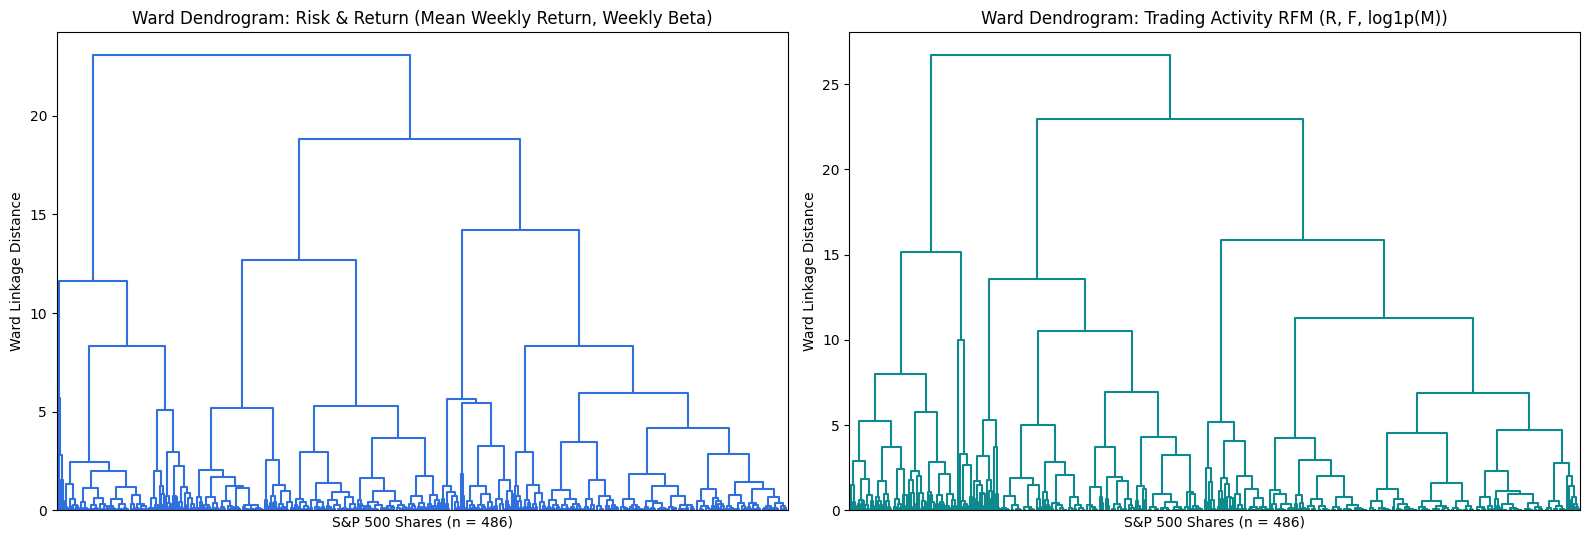

Top 10 Ward merge distances (Risk-Return): [23.07, 18.8, 14.21, 12.67, 11.6, 8.34, 8.31, 5.93, 5.71, 5.63]
Top 10 Ward merge distances (RFM):         [26.71, 22.99, 15.84, 15.15, 13.58, 11.29, 10.54, 9.97, 7.97, 6.93]

=== Task 2.2 Ward Evaluation (Risk & Return, k = 2..8) ===


,Matrix,k,Silhouette,Min_Size,Max_Size,Cluster_Sizes
0,Risk_Return,2,0.3395,92,394,"{1: 394, 2: 92}"
1,Risk_Return,3,0.2738,92,230,"{1: 230, 2: 164, 3: 92}"
2,Risk_Return,4,0.2821,48,182,"{1: 182, 2: 164, 3: 48, 4: 92}"
3,Risk_Return,5,0.3041,48,182,"{1: 182, 2: 66, 3: 98, 4: 48, 5: 92}"
4,Risk_Return,6,0.3204,5,182,"{1: 182, 2: 66, 3: 98, 4: 48, 5: 87, 6: 5}"
5,Risk_Return,7,0.3240,5,160,"{1: 160, 2: 66, 3: 98, 4: 48, 5: 22, 6: 87, 7: 5}"
6,Risk_Return,8,0.3208,5,160,"{1: 160, 2: 66, 3: 98, 4: 48, 5: 22, 6: 56, 7:..."



=== Task 2.2 Ward Evaluation (RFM, k = 2..8) ===


,Matrix,k,Silhouette,Min_Size,Max_Size,Cluster_Sizes
0,RFM,2,0.3680,82,404,"{1: 404, 2: 82}"
1,RFM,3,0.3040,82,250,"{1: 154, 2: 250, 3: 82}"
2,RFM,4,0.2888,43,207,"{1: 154, 2: 207, 3: 82, 4: 43}"
3,RFM,5,0.3050,10,207,"{1: 154, 2: 207, 3: 72, 4: 43, 5: 10}"
4,RFM,6,0.3144,10,207,"{1: 136, 2: 207, 3: 18, 4: 72, 5: 43, 6: 10}"
5,RFM,7,0.2917,10,141,"{1: 136, 2: 66, 3: 18, 4: 72, 5: 141, 6: 43, 7..."
6,RFM,8,0.3021,10,141,"{1: 57, 2: 66, 3: 79, 4: 18, 5: 72, 6: 141, 7:..."


In [12]:
# Task 2.2: Ward hierarchical clustering (Euclidean distance) on both matrices
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score

Z_rr = linkage(X_rr_scaled, method='ward', metric='euclidean')
Z_rfm = linkage(X_rfm_scaled, method='ward', metric='euclidean')

# Plot one dendrogram per feature matrix (single colour avoids relying on default threshold)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

dendrogram(Z_rr, no_labels=True, color_threshold=0, above_threshold_color='#2f6fde', ax=axes[0])
axes[0].set_title('Ward Dendrogram: Risk & Return (Mean Weekly Return, Weekly Beta)')
axes[0].set_xlabel('S&P 500 Shares (n = 486)')
axes[0].set_ylabel('Ward Linkage Distance')

dendrogram(Z_rfm, no_labels=True, color_threshold=0, above_threshold_color='#0e8a8f', ax=axes[1])
axes[1].set_title('Ward Dendrogram: Trading Activity RFM (R, F, log1p(M))')
axes[1].set_xlabel('S&P 500 Shares (n = 486)')
axes[1].set_ylabel('Ward Linkage Distance')

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_2_ward_dendrograms_combined.png', dpi=150)
plt.show()

# Save each dendrogram individually at 150 DPI for report use
for Z, title, fname, col in [
    (Z_rr, 'Ward Hierarchical Clustering Dendrogram: Risk & Return (n = 486)', 'task2_2_dendrogram_risk_return.png', '#2f6fde'),
    (Z_rfm, 'Ward Hierarchical Clustering Dendrogram: RFM Trading Activity (n = 486)', 'task2_2_dendrogram_rfm.png', '#0e8a8f'),
]:
    plt.figure(figsize=(10, 4.8))
    dendrogram(Z, no_labels=True, color_threshold=0, above_threshold_color=col)
    plt.title(title)
    plt.xlabel('S&P 500 Shares (n = 486)')
    plt.ylabel('Ward Linkage Distance')
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=150)
    plt.close()

# Inspect top 10 Ward merge distances (from largest down)
print('Top 10 Ward merge distances (Risk-Return):', np.round(Z_rr[-10:, 2][::-1], 2).tolist())
print('Top 10 Ward merge distances (RFM):        ', np.round(Z_rfm[-10:, 2][::-1], 2).tolist())

# Evaluate Ward cluster counts k = 2 to 8 using silhouette score and cluster sizes
def evaluate_ward(Z, X_scaled, matrix_name):
    rows = []
    for k in range(2, 9):
        labels = cut_tree(Z, n_clusters=k).ravel() + 1
        sil = silhouette_score(X_scaled, labels)
        sizes = pd.Series(labels).value_counts().sort_index()
        rows.append({
            'Matrix': matrix_name,
            'k': k,
            'Silhouette': round(sil, 4),
            'Min_Size': int(sizes.min()),
            'Max_Size': int(sizes.max()),
            'Cluster_Sizes': {int(c): int(n) for c, n in sizes.items()}
        })
    return pd.DataFrame(rows)

ward_rr_eval = evaluate_ward(Z_rr, X_rr_scaled, 'Risk_Return')
ward_rfm_eval = evaluate_ward(Z_rfm, X_rfm_scaled, 'RFM')

print('\n=== Task 2.2 Ward Evaluation (Risk & Return, k = 2..8) ===')
display(ward_rr_eval)
print('\n=== Task 2.2 Ward Evaluation (RFM, k = 2..8) ===')
display(ward_rfm_eval)

pd.concat([ward_rr_eval, ward_rfm_eval], ignore_index=True).to_csv(OUTPUT_DIR / 'task2_2_ward_k_evaluation.csv', index=False)

=== Task 2.3 K-Means Evaluation (Risk & Return, k = 2..8) ===


,Matrix,k,Inertia_WCSS,Silhouette,Min_Size,Max_Size,Cluster_Sizes
0,Risk_Return,2,621.63,0.3870,143,343,"{1: 143, 2: 343}"
1,Risk_Return,3,461.18,0.3289,119,202,"{1: 202, 2: 165, 3: 119}"
2,Risk_Return,4,371.58,0.3270,40,160,"{1: 132, 2: 154, 3: 40, 4: 160}"
3,Risk_Return,5,309.61,0.3406,27,166,"{1: 112, 2: 166, 3: 131, 4: 27, 5: 50}"
4,Risk_Return,6,265.45,0.3339,5,158,"{1: 56, 2: 113, 3: 158, 4: 111, 5: 43, 6: 5}"
5,Risk_Return,7,227.48,0.3315,5,143,"{1: 83, 2: 74, 3: 143, 4: 85, 5: 5, 6: 48, 7: 48}"
6,Risk_Return,8,194.36,0.3542,5,136,"{1: 136, 2: 43, 3: 76, 4: 78, 5: 5, 6: 29, 7: ..."



=== Task 2.3 K-Means Evaluation (RFM, k = 2..8) ===


,Matrix,k,Inertia_WCSS,Silhouette,Min_Size,Max_Size,Cluster_Sizes
0,RFM,2,1066.83,0.4231,68,418,"{1: 418, 2: 68}"
1,RFM,3,796.61,0.3250,64,270,"{1: 270, 2: 152, 3: 64}"
2,RFM,4,609.83,0.3409,61,212,"{1: 122, 2: 61, 3: 212, 4: 91}"
3,RFM,5,514.71,0.3578,11,198,"{1: 68, 2: 122, 3: 87, 4: 11, 5: 198}"
4,RFM,6,437.42,0.3455,11,141,"{1: 104, 2: 120, 3: 141, 4: 69, 5: 11, 6: 41}"
5,RFM,7,386.29,0.3474,1,141,"{1: 141, 2: 41, 3: 104, 4: 120, 5: 1, 6: 68, 7..."
6,RFM,8,342.17,0.3503,1,140,"{1: 15, 2: 106, 3: 64, 4: 66, 5: 1, 6: 11, 7: ..."


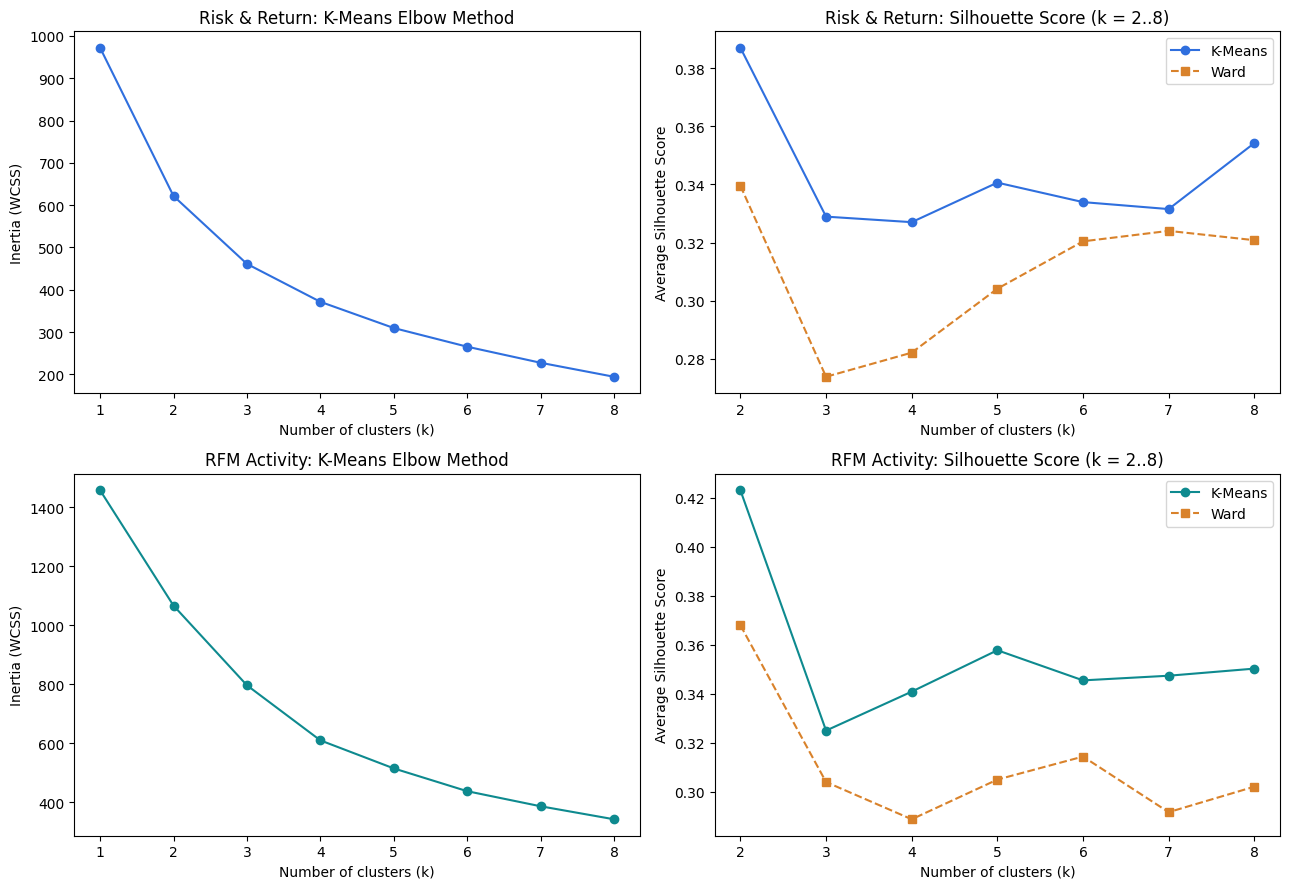

In [13]:
# Task 2.3: K-Means clustering on both matrices (k = 2..8, seeded, multiple initialisations)
from sklearn.cluster import KMeans

SEED = 42
N_INIT = 20

def evaluate_kmeans(X_scaled, matrix_name):
    rows = []
    inertia_all = {}
    # Include k = 1 inertia for a complete Elbow curve
    km1 = KMeans(n_clusters=1, init='k-means++', n_init=N_INIT, random_state=SEED).fit(X_scaled)
    inertia_all[1] = km1.inertia_

    for k in range(2, 9):
        km = KMeans(n_clusters=k, init='k-means++', n_init=N_INIT, random_state=SEED).fit(X_scaled)
        inertia_all[k] = km.inertia_
        labels = km.labels_ + 1
        sil = silhouette_score(X_scaled, labels)
        sizes = pd.Series(labels).value_counts().sort_index()
        rows.append({
            'Matrix': matrix_name,
            'k': k,
            'Inertia_WCSS': round(km.inertia_, 2),
            'Silhouette': round(sil, 4),
            'Min_Size': int(sizes.min()),
            'Max_Size': int(sizes.max()),
            'Cluster_Sizes': {int(c): int(n) for c, n in sizes.items()}
        })
    return pd.DataFrame(rows), inertia_all

km_rr_eval, inertia_rr = evaluate_kmeans(X_rr_scaled, 'Risk_Return')
km_rfm_eval, inertia_rfm = evaluate_kmeans(X_rfm_scaled, 'RFM')

print('=== Task 2.3 K-Means Evaluation (Risk & Return, k = 2..8) ===')
display(km_rr_eval)
print('\n=== Task 2.3 K-Means Evaluation (RFM, k = 2..8) ===')
display(km_rfm_eval)

pd.concat([km_rr_eval, km_rfm_eval], ignore_index=True).to_csv(OUTPUT_DIR / 'task2_3_kmeans_k_evaluation.csv', index=False)

# Plot Elbow (Inertia) and Silhouette comparisons (Ward vs K-Means) for both matrices
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Risk & Return Elbow and Silhouette
axes[0, 0].plot(list(inertia_rr.keys()), list(inertia_rr.values()), marker='o', color='#2f6fde')
axes[0, 0].set_title('Risk & Return: K-Means Elbow Method')
axes[0, 0].set_xlabel('Number of clusters (k)')
axes[0, 0].set_ylabel('Inertia (WCSS)')

axes[0, 1].plot(km_rr_eval['k'], km_rr_eval['Silhouette'], marker='o', label='K-Means', color='#2f6fde')
axes[0, 1].plot(ward_rr_eval['k'], ward_rr_eval['Silhouette'], marker='s', linestyle='--', label='Ward', color='#d9822b')
axes[0, 1].set_title('Risk & Return: Silhouette Score (k = 2..8)')
axes[0, 1].set_xlabel('Number of clusters (k)')
axes[0, 1].set_ylabel('Average Silhouette Score')
axes[0, 1].legend()

# RFM Elbow and Silhouette
axes[1, 0].plot(list(inertia_rfm.keys()), list(inertia_rfm.values()), marker='o', color='#0e8a8f')
axes[1, 0].set_title('RFM Activity: K-Means Elbow Method')
axes[1, 0].set_xlabel('Number of clusters (k)')
axes[1, 0].set_ylabel('Inertia (WCSS)')

axes[1, 1].plot(km_rfm_eval['k'], km_rfm_eval['Silhouette'], marker='o', label='K-Means', color='#0e8a8f')
axes[1, 1].plot(ward_rfm_eval['k'], ward_rfm_eval['Silhouette'], marker='s', linestyle='--', label='Ward', color='#d9822b')
axes[1, 1].set_title('RFM Activity: Silhouette Score (k = 2..8)')
axes[1, 1].set_xlabel('Number of clusters (k)')
axes[1, 1].set_ylabel('Average Silhouette Score')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_2_3_elbow_silhouette.png', dpi=150)
plt.show()

In [14]:
# Preview original-unit profiles for k = 3, 4, 5 to check business interpretability
for k in [3, 4, 5]:
    print(f'\n================ CANDIDATE k = {k} ================')
    rr_w = cut_tree(Z_rr, n_clusters=k).ravel() + 1
    rr_km = KMeans(n_clusters=k, init='k-means++', n_init=N_INIT, random_state=SEED).fit(X_rr_scaled).labels_ + 1

    print(f'-- Risk & Return: Ward (k={k}) --')
    tmp = X_rr_raw.copy()
    tmp['Cluster'] = rr_w
    display(tmp.groupby('Cluster').agg(
        Count=('Weekly_Beta', 'count'),
        Mean_Ret_Pct=('Mean_Weekly_Return', lambda s: round(s.mean() * 100, 3)),
        Mean_Beta=('Weekly_Beta', lambda s: round(s.mean(), 3))
    ))

    print(f'-- Risk & Return: K-Means (k={k}) --')
    tmp['Cluster'] = rr_km
    display(tmp.groupby('Cluster').agg(
        Count=('Weekly_Beta', 'count'),
        Mean_Ret_Pct=('Mean_Weekly_Return', lambda s: round(s.mean() * 100, 3)),
        Mean_Beta=('Weekly_Beta', lambda s: round(s.mean(), 3))
    ))

    rfm_w = cut_tree(Z_rfm, n_clusters=k).ravel() + 1
    rfm_km = KMeans(n_clusters=k, init='k-means++', n_init=N_INIT, random_state=SEED).fit(X_rfm_scaled).labels_ + 1

    print(f'-- RFM Activity: Ward (k={k}) --')
    tmp_r = X_rfm_raw.copy()
    tmp_r['Cluster'] = rfm_w
    display(tmp_r.groupby('Cluster').agg(
        Count=('Recency', 'count'),
        Mean_R=('Recency', lambda s: round(s.mean(), 1)),
        Mean_F=('Frequency', lambda s: round(s.mean(), 2)),
        Mean_M_USD_B=('Monetary', lambda s: round(s.mean() / 1e9, 2)),
        Median_M_USD_B=('Monetary', lambda s: round(s.median() / 1e9, 2))
    ))

    print(f'-- RFM Activity: K-Means (k={k}) --')
    tmp_r['Cluster'] = rfm_km
    display(tmp_r.groupby('Cluster').agg(
        Count=('Recency', 'count'),
        Mean_R=('Recency', lambda s: round(s.mean(), 1)),
        Mean_F=('Frequency', lambda s: round(s.mean(), 2)),
        Mean_M_USD_B=('Monetary', lambda s: round(s.mean() / 1e9, 2)),
        Median_M_USD_B=('Monetary', lambda s: round(s.median() / 1e9, 2))
    ))


================ CANDIDATE k = 3 ================
-- Risk & Return: Ward (k=3) --


,Count,Mean_Ret_Pct,Mean_Beta
Cluster,,,
1,230,0.146,1.110
2,164,0.287,0.601
3,92,0.632,1.298


-- Risk & Return: K-Means (k=3) --


,Count,Mean_Ret_Pct,Mean_Beta
Cluster,,,
1,202,0.259,0.631
2,165,0.095,1.139
3,119,0.596,1.326


-- RFM Activity: Ward (k=3) --


,Count,Mean_R,Mean_F,Mean_M_USD_B,Median_M_USD_B
Cluster,,,,,
1,154,13.7,2.86,80.15,39.70
2,250,12.1,3.36,11.76,11.18
3,82,58.3,2.10,47.16,17.85


... (14 outputs left out)

-- RFM Activity: Ward (k=5) --


,Count,Mean_R,Mean_F,Mean_M_USD_B,Median_M_USD_B
Cluster,,,,,
1,154,13.7,2.86,80.15,39.70
2,207,11.1,2.94,11.10,10.79
3,72,50.2,2.39,25.97,17.68
4,43,16.8,5.37,14.96,14.43
5,10,116.8,0.00,199.74,23.79


-- RFM Activity: K-Means (k=5) --


,Count,Mean_R,Mean_F,Mean_M_USD_B,Median_M_USD_B
Cluster,,,,,
1,68,50.6,2.19,26.44,19.55
2,122,13.9,4.55,15.02,12.83
3,87,14.1,3.24,120.71,63.10
4,11,113.9,0.09,184.00,24.82
5,198,11.6,2.35,15.13,13.21


In [15]:
# Task 2.4: Fit all four baseline clustering solutions (k = 4) on common 486 shares
from sklearn.metrics import adjusted_rand_score

K_RR = 4
K_RFM = 4

# Fit Ward hierarchical models (Euclidean distance)
rr_ward_labels = cut_tree(Z_rr, n_clusters=K_RR).ravel() + 1
rfm_ward_labels = cut_tree(Z_rfm, n_clusters=K_RFM).ravel() + 1

# Fit K-Means models (fixed seed, multiple k-means++ initialisations)
km_rr_model = KMeans(n_clusters=K_RR, init='k-means++', n_init=N_INIT, random_state=SEED).fit(X_rr_scaled)
km_rfm_model = KMeans(n_clusters=K_RFM, init='k-means++', n_init=N_INIT, random_state=SEED).fit(X_rfm_scaled)
rr_km_labels = km_rr_model.labels_ + 1
rfm_km_labels = km_rfm_model.labels_ + 1

# Attach all four baseline cluster assignments to the common feature table
results_df = feature_df.copy()
results_df['RR_Ward_Cluster'] = rr_ward_labels
results_df['RR_KMeans_Cluster'] = rr_km_labels
results_df['RFM_Ward_Cluster'] = rfm_ward_labels
results_df['RFM_KMeans_Cluster'] = rfm_km_labels

# Helper to produce original-unit cluster profile tables
def profile_rr(df, col):
    return df.groupby(col).agg(
        Count=('Ticker', 'count'),
        Mean_Ret_Pct=('Mean_Weekly_Return', lambda s: round(s.mean() * 100, 3)),
        Median_Ret_Pct=('Mean_Weekly_Return', lambda s: round(s.median() * 100, 3)),
        Mean_Beta=('Weekly_Beta', lambda s: round(s.mean(), 3)),
        Median_Beta=('Weekly_Beta', lambda s: round(s.median(), 3))
    )

def profile_rfm(df, col):
    return df.groupby(col).agg(
        Count=('Ticker', 'count'),
        Mean_R=('Recency', lambda s: round(s.mean(), 1)),
        Median_R=('Recency', lambda s: round(s.median(), 1)),
        Mean_F=('Frequency', lambda s: round(s.mean(), 2)),
        Median_F=('Frequency', lambda s: round(s.median(), 1)),
        Mean_M_USD_B=('Monetary', lambda s: round(s.mean() / 1e9, 2)),
        Median_M_USD_B=('Monetary', lambda s: round(s.median() / 1e9, 2))
    )

rr_ward_prof = profile_rr(results_df, 'RR_Ward_Cluster')
rr_km_prof = profile_rr(results_df, 'RR_KMeans_Cluster')
rfm_ward_prof = profile_rfm(results_df, 'RFM_Ward_Cluster')
rfm_km_prof = profile_rfm(results_df, 'RFM_KMeans_Cluster')

print('=== Risk & Return Profiles (Original Units) ===')
print('\n1. Ward Agglomerative (k = 4):')
display(rr_ward_prof)
print('\n2. K-Means (k = 4):')
display(rr_km_prof)

print('\n=== RFM Trading Activity Profiles (Original Units) ===')
print('\n3. Ward Agglomerative (k = 4):')
display(rfm_ward_prof)
print('\n4. K-Means (k = 4):')
display(rfm_km_prof)

# Compare Ward vs K-Means on the exact same 486 shares using ARI and cross-tabs
ari_rr_alg = adjusted_rand_score(results_df['RR_Ward_Cluster'], results_df['RR_KMeans_Cluster'])
ari_rfm_alg = adjusted_rand_score(results_df['RFM_Ward_Cluster'], results_df['RFM_KMeans_Cluster'])
ari_rr_vs_rfm_ward = adjusted_rand_score(results_df['RR_Ward_Cluster'], results_df['RFM_Ward_Cluster'])

print(f'\nAlgorithm Agreement (Ward vs K-Means) — Risk & Return ARI: {ari_rr_alg:.4f}')
print(f'Algorithm Agreement (Ward vs K-Means) — RFM Activity ARI:  {ari_rfm_alg:.4f}')
print(f'Cross-Matrix Agreement (Ward Risk-Return vs Ward RFM) ARI: {ari_rr_vs_rfm_ward:.4f}')

print('\nCross-tab: Risk & Return (Ward rows vs K-Means columns):')
display(pd.crosstab(results_df['RR_Ward_Cluster'], results_df['RR_KMeans_Cluster'], margins=True))

print('\nCross-tab: RFM Activity (Ward rows vs K-Means columns):')
display(pd.crosstab(results_df['RFM_Ward_Cluster'], results_df['RFM_KMeans_Cluster'], margins=True))

# Save original-unit profile tables
rr_ward_prof.to_csv(OUTPUT_DIR / 'profile_rr_ward_k4.csv')
rr_km_prof.to_csv(OUTPUT_DIR / 'profile_rr_kmeans_k4.csv')
rfm_ward_prof.to_csv(OUTPUT_DIR / 'profile_rfm_ward_k4.csv')
rfm_km_prof.to_csv(OUTPUT_DIR / 'profile_rfm_kmeans_k4.csv')

=== Risk & Return Profiles (Original Units) ===

1. Ward Agglomerative (k = 4):


,Count,Mean_Ret_Pct,Median_Ret_Pct,Mean_Beta,Median_Beta
RR_Ward_Cluster,,,,,
1,182,0.132,0.166,0.973,0.964
2,164,0.287,0.327,0.601,0.578
3,48,0.200,0.252,1.628,1.514
4,92,0.632,0.550,1.298,1.218



2. K-Means (k = 4):


,Count,Mean_Ret_Pct,Median_Ret_Pct,Mean_Beta,Median_Beta
RR_KMeans_Cluster,,,,,
1,132,0.084,0.113,1.203,1.142
2,154,0.169,0.187,0.577,0.577
3,40,0.725,0.701,1.708,1.681
4,160,0.454,0.433,0.983,0.985



=== RFM Trading Activity Profiles (Original Units) ===

3. Ward Agglomerative (k = 4):


,Count,Mean_R,Median_R,Mean_F,Median_F,Mean_M_USD_B,Median_M_USD_B
RFM_Ward_Cluster,,,,,,,
1,154,13.7,11.0,2.86,3.0,80.15,39.70
2,207,11.1,11.0,2.94,3.0,11.10,10.79
3,82,58.3,54.5,2.10,2.0,47.16,17.85
4,43,16.8,11.0,5.37,5.0,14.96,14.43


... (2 outputs left out)


Algorithm Agreement (Ward vs K-Means) — Risk & Return ARI: 0.2666
Algorithm Agreement (Ward vs K-Means) — RFM Activity ARI:  0.3430
Cross-Matrix Agreement (Ward Risk-Return vs Ward RFM) ARI: 0.0389

Cross-tab: Risk & Return (Ward rows vs K-Means columns):


RR_KMeans_Cluster,1,2,3,4,All
RR_Ward_Cluster,,,,,
1,97,51,0,34,182
2,0,103,0,61,164
3,35,0,12,1,48
4,0,0,28,64,92
All,132,154,40,160,486



Cross-tab: RFM Activity (Ward rows vs K-Means columns):


RFM_KMeans_Cluster,1,2,3,4,All
RFM_Ward_Cluster,,,,,
1,14,4,52,84,154
2,61,0,146,0,207
3,4,57,14,7,82
4,43,0,0,0,43
All,122,61,212,91,486


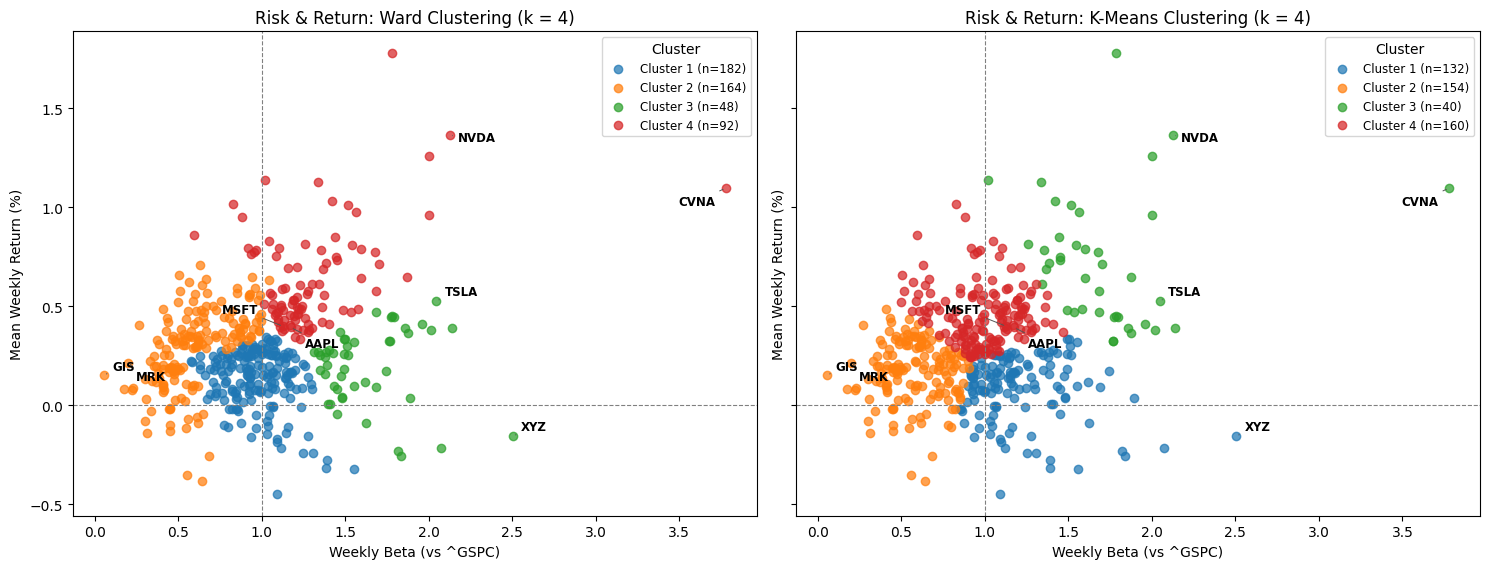

=== RFM PCA Explained Variance & Loadings ===
PC1 explained variance:   45.79%
PC2 explained variance:   33.65%
Total 2D variance kept:   79.44%


,PC1,PC2
Recency,0.7113,0.0228
Frequency,-0.6499,0.4021
LogMonetary,0.2678,0.9153


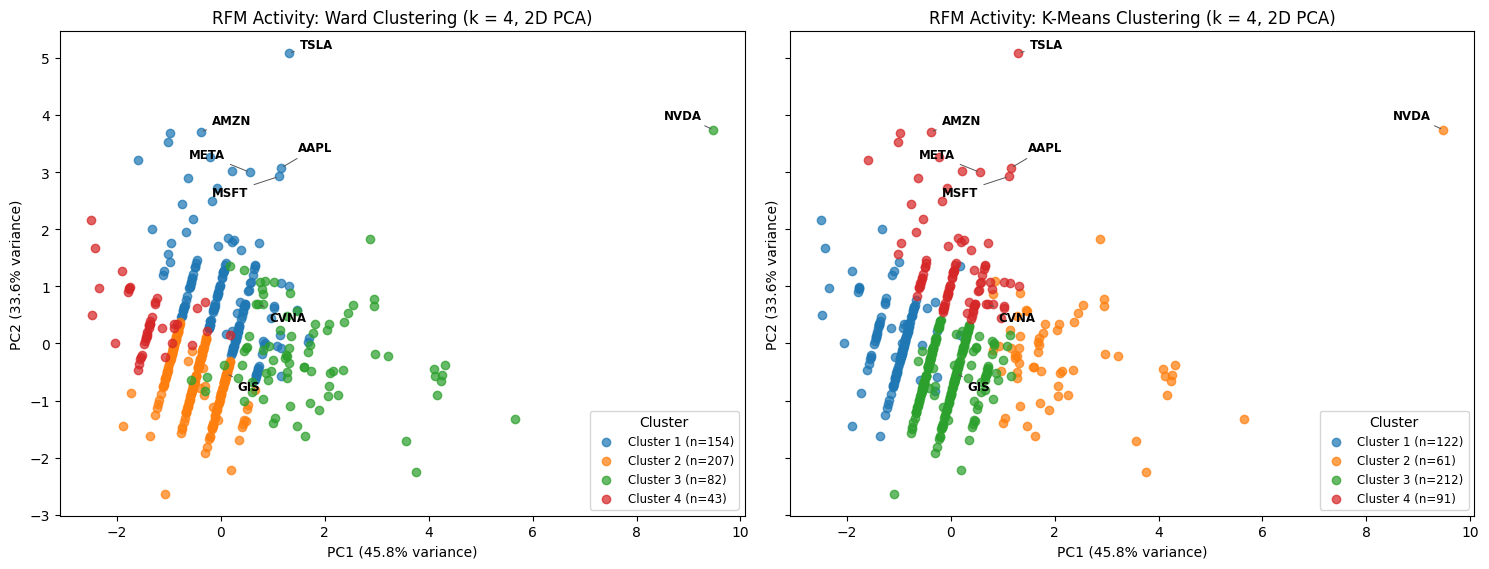

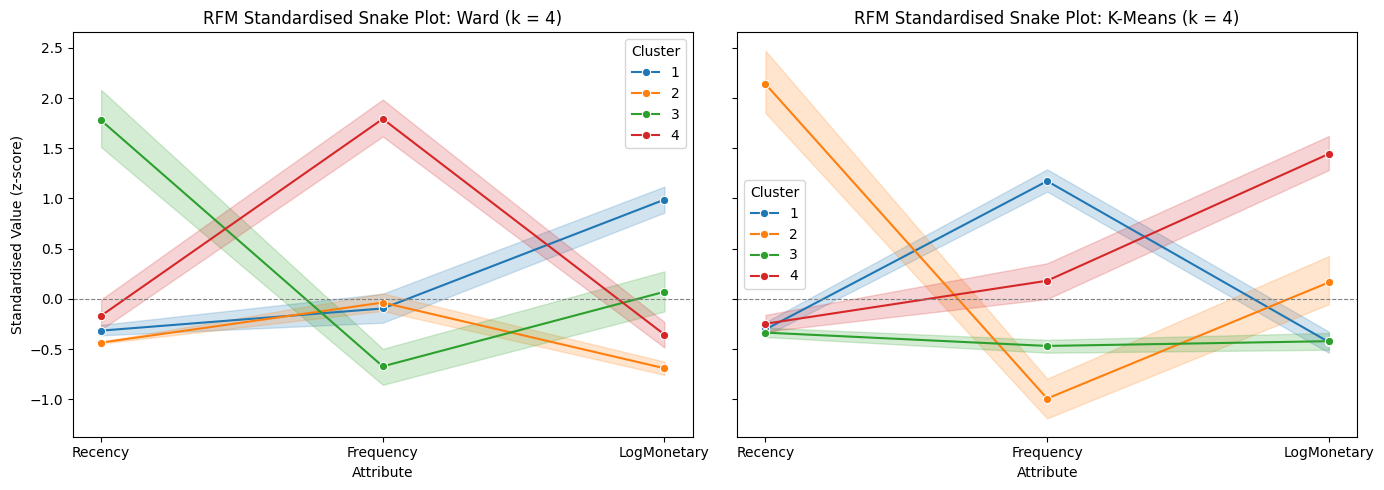

In [16]:
# Task 2.4: Labelled 2D visualisations (Risk-Return scatter + RFM 2D PCA + Snake plots)
from sklearn.decomposition import PCA

# 1. Risk & Return 2D scatter plots in original units (custom offsets prevent label overlap)
rr_offsets = {
    'NVDA': (6, -4), 'CVNA': (-34, -12), 'TSLA': (6, 4), 'XYZ': (6, 4),
    'AAPL': (10, -14), 'MSFT': (-44, 10), 'GIS': (6, 4), 'MRK': (6, -12)
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharex=True, sharey=True)
for ax, col, title in [
    (axes[0], 'RR_Ward_Cluster', 'Risk & Return: Ward Clustering (k = 4)'),
    (axes[1], 'RR_KMeans_Cluster', 'Risk & Return: K-Means Clustering (k = 4)')
]:
    for c_id, grp in results_df.groupby(col):
        ax.scatter(grp['Weekly_Beta'], grp['Mean_Weekly_Return'] * 100, alpha=0.72, s=36,
                   label=f'Cluster {c_id} (n={len(grp)})')
    for t, (dx, dy) in rr_offsets.items():
        if t in results_df['Ticker'].values:
            row = results_df.loc[results_df['Ticker'] == t].iloc[0]
            ax.annotate(t, (row['Weekly_Beta'], row['Mean_Weekly_Return'] * 100),
                        xytext=(dx, dy), textcoords='offset points', fontsize=8.5, fontweight='bold',
                        arrowprops=dict(arrowstyle='-', color='#555555', lw=0.7))
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.axvline(1.0, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel('Weekly Beta (vs ^GSPC)')
    ax.set_ylabel('Mean Weekly Return (%)')
    ax.legend(title='Cluster', fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_4_risk_return_scatter_ward_vs_kmeans.png', dpi=150)
plt.show()

# 2. RFM 2D PCA projection (reduces 3 standardised features to 2D)
pca_rfm = PCA(n_components=2, random_state=SEED)
rfm_pcs = pca_rfm.fit_transform(X_rfm_scaled)
results_df['RFM_PC1'] = rfm_pcs[:, 0]
results_df['RFM_PC2'] = rfm_pcs[:, 1]

pca_loadings = pd.DataFrame(
    pca_rfm.components_.T,
    index=X_rfm_scaled.columns,
    columns=['PC1', 'PC2']
).round(4)
print('=== RFM PCA Explained Variance & Loadings ===')
print(f'PC1 explained variance:   {pca_rfm.explained_variance_ratio_[0]*100:.2f}%')
print(f'PC2 explained variance:   {pca_rfm.explained_variance_ratio_[1]*100:.2f}%')
print(f'Total 2D variance kept:   {pca_rfm.explained_variance_ratio_.sum()*100:.2f}%')
display(pca_loadings)
pca_loadings.to_csv(OUTPUT_DIR / 'task2_4_rfm_pca_loadings.csv')

rfm_offsets = {
    'NVDA': (-36, 8), 'TSLA': (8, 4), 'AMZN': (8, 6), 'AAPL': (12, 12),
    'MSFT': (-48, -14), 'META': (-44, 10), 'CVNA': (8, -12), 'GIS': (8, -12)
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharex=True, sharey=True)
for ax, col, title in [
    (axes[0], 'RFM_Ward_Cluster', 'RFM Activity: Ward Clustering (k = 4, 2D PCA)'),
    (axes[1], 'RFM_KMeans_Cluster', 'RFM Activity: K-Means Clustering (k = 4, 2D PCA)')
]:
    for c_id, grp in results_df.groupby(col):
        ax.scatter(grp['RFM_PC1'], grp['RFM_PC2'], alpha=0.72, s=36,
                   label=f'Cluster {c_id} (n={len(grp)})')
    for t, (dx, dy) in rfm_offsets.items():
        if t in results_df['Ticker'].values:
            row = results_df.loc[results_df['Ticker'] == t].iloc[0]
            ax.annotate(t, (row['RFM_PC1'], row['RFM_PC2']),
                        xytext=(dx, dy), textcoords='offset points', fontsize=8.5, fontweight='bold',
                        arrowprops=dict(arrowstyle='-', color='#555555', lw=0.7))
    ax.set_title(title)
    ax.set_xlabel(f'PC1 ({pca_rfm.explained_variance_ratio_[0]*100:.1f}% variance)')
    ax.set_ylabel(f'PC2 ({pca_rfm.explained_variance_ratio_[1]*100:.1f}% variance)')
    ax.legend(title='Cluster', fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_4_rfm_pca_ward_vs_kmeans.png', dpi=150)
plt.show()

# 3. Standardised RFM snake plots (Week 2 tutorial style) for Ward and K-Means
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, labels, title in [
    (axes[0], rfm_ward_labels, 'RFM Standardised Snake Plot: Ward (k = 4)'),
    (axes[1], rfm_km_labels, 'RFM Standardised Snake Plot: K-Means (k = 4)')
]:
    df_norm = X_rfm_scaled.copy()
    df_norm['Ticker'] = df_norm.index
    df_norm['Cluster'] = labels
    df_melt = pd.melt(
        df_norm,
        id_vars=['Ticker', 'Cluster'],
        value_vars=['Recency', 'Frequency', 'LogMonetary'],
        var_name='Attribute',
        value_name='Standardised_Value'
    )
    sns.lineplot(x='Attribute', y='Standardised_Value', hue='Cluster', marker='o',
                 palette='tab10', data=df_melt, ax=ax)
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel('Standardised Value (z-score)')

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_4_rfm_snake_plots.png', dpi=150)
plt.show()

=== Task 2.5.1 Pearson Correlations (Inputs to Clustering) ===


,Recency,Frequency,LogMonetary
Recency,1.0000,-0.3463,0.1524
Frequency,-0.3463,1.0000,0.0128
LogMonetary,0.1524,0.0128,1.0000



=== Spearman Rank Correlations (Check for Skewed Recency) ===


,Recency,Frequency,LogMonetary
Recency,1.0000,-0.1958,0.1372
Frequency,-0.1958,1.0000,-0.0476
LogMonetary,0.1372,-0.0476,1.0000


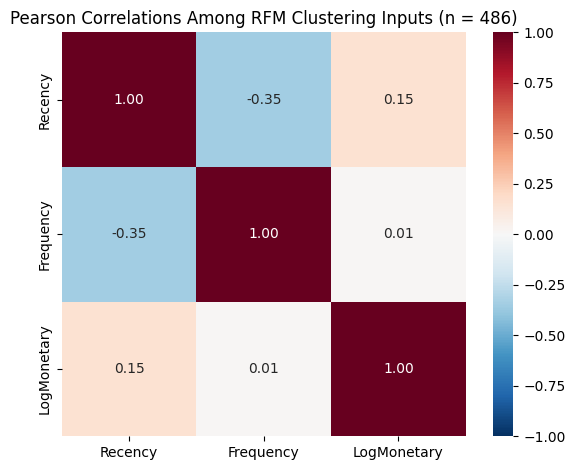

In [17]:
# Task 2.5.1: Correlation analysis among Recency, Frequency, and log1p(Monetary)
rfm_corr_input = X_rfm_trans.rename(columns={'Monetary': 'LogMonetary'})[['Recency', 'Frequency', 'LogMonetary']]

pearson_corr = rfm_corr_input.corr(method='pearson').round(4)
spearman_corr = rfm_corr_input.corr(method='spearman').round(4)

print('=== Task 2.5.1 Pearson Correlations (Inputs to Clustering) ===')
display(pearson_corr)
print('\n=== Spearman Rank Correlations (Check for Skewed Recency) ===')
display(spearman_corr)

pearson_corr.to_csv(OUTPUT_DIR / 'task2_5_1_rfm_pearson_corr.csv')
spearman_corr.to_csv(OUTPUT_DIR / 'task2_5_1_rfm_spearman_corr.csv')

# Plot correlation heatmap
plt.figure(figsize=(6, 4.8))
sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True)
plt.title('Pearson Correlations Among RFM Clustering Inputs (n = 486)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_5_1_rfm_correlation_heatmap.png', dpi=150)
plt.show()

=== Task 2.5.2 Monetary Removal Sensitivity (Ward, k = 4, n = 486) ===
Adjusted Rand Index (Full RFM vs R-F Only): 0.2026
Silhouette Score (Full RFM):                0.2888
Silhouette Score (R-F Only):                0.5156

Cross-tab: Full RFM Ward (rows) vs R-F Only Ward (columns):


RF_Only_Ward_Cluster,1,2,3,4,All
RFM_Ward_Cluster,,,,,
1,86,59,9,0,154
2,141,66,0,0,207
3,3,0,69,10,82
4,42,0,1,0,43
All,272,125,79,10,486



Full RFM Ward Cluster Profiles (including Monetary USD Billions):


,Count,Mean_R,Median_R,Mean_F,Median_F,Mean_M_USD_B,Median_M_USD_B
RFM_Ward_Cluster,,,,,,,
1,154,13.7,11.0,2.86,3.0,80.15,39.70
2,207,11.1,11.0,2.94,3.0,11.10,10.79
3,82,58.3,54.5,2.10,2.0,47.16,17.85
4,43,16.8,11.0,5.37,5.0,14.96,14.43



R-F Only Ward Cluster Profiles (evaluating Monetary USD Billions externally):


,Count,Mean_R,Median_R,Mean_F,Median_F,Mean_M_USD_B,Median_M_USD_B
RF_Only_Ward_Cluster,,,,,,,
1,272,12.9,11,3.86,4.0,39.40,14.86
2,125,11.0,11,1.80,2.0,34.34,17.70
3,79,48.9,49,2.27,2.0,27.14,20.13
4,10,116.8,102,0.00,0.0,199.74,23.79



Share of log1p(Monetary) variance explained by clusters (eta-squared):
  Full RFM Ward clusters:  52.44%
  R-F Only Ward clusters:  0.50%


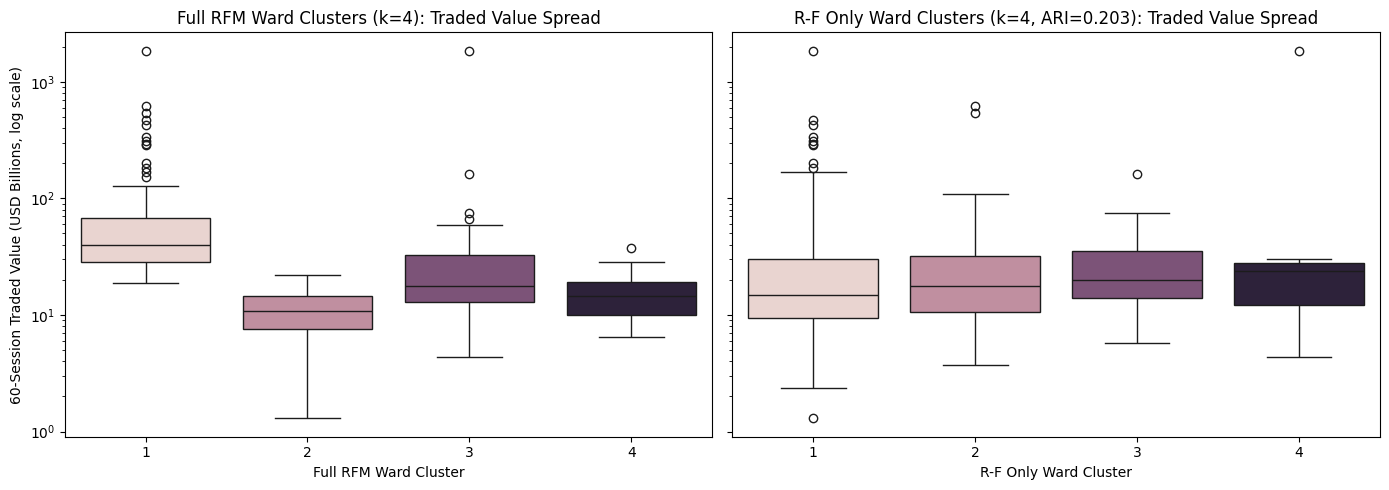

In [18]:
# Task 2.5.2: Repeat selected Ward RFM solution using R and F only (standardised afresh, k = 4)
X_rf_only_raw = X_rfm_raw[['Recency', 'Frequency']].copy()

# Standardise the reduced 2-feature matrix afresh
scaler_rf = StandardScaler()
X_rf_only_scaled = pd.DataFrame(
    scaler_rf.fit_transform(X_rf_only_raw),
    index=X_rf_only_raw.index,
    columns=['Recency', 'Frequency']
)

# Fit Ward hierarchical clustering with Euclidean distance and cut at same k = 4
Z_rf_only = linkage(X_rf_only_scaled, method='ward', metric='euclidean')
rf_only_ward_labels = cut_tree(Z_rf_only, n_clusters=K_RFM).ravel() + 1

results_df['RF_Only_Ward_Cluster'] = rf_only_ward_labels

# Compare full RFM Ward vs reduced RF-only Ward memberships via Adjusted Rand Index
ari_monetary_removal = adjusted_rand_score(results_df['RFM_Ward_Cluster'], results_df['RF_Only_Ward_Cluster'])
sil_rfm_full = silhouette_score(X_rfm_scaled, results_df['RFM_Ward_Cluster'])
sil_rf_only = silhouette_score(X_rf_only_scaled, results_df['RF_Only_Ward_Cluster'])

print(f'=== Task 2.5.2 Monetary Removal Sensitivity (Ward, k = {K_RFM}, n = 486) ===')
print(f'Adjusted Rand Index (Full RFM vs R-F Only): {ari_monetary_removal:.4f}')
print(f'Silhouette Score (Full RFM):                {sil_rfm_full:.4f}')
print(f'Silhouette Score (R-F Only):                {sil_rf_only:.4f}')

print('\nCross-tab: Full RFM Ward (rows) vs R-F Only Ward (columns):')
crosstab_sens = pd.crosstab(results_df['RFM_Ward_Cluster'], results_df['RF_Only_Ward_Cluster'], margins=True)
display(crosstab_sens)

# Compare cluster traded-value (Monetary) profiles before and after removing Monetary
rf_only_prof = profile_rfm(results_df, 'RF_Only_Ward_Cluster')
print('\nFull RFM Ward Cluster Profiles (including Monetary USD Billions):')
display(rfm_ward_prof)
print('\nR-F Only Ward Cluster Profiles (evaluating Monetary USD Billions externally):')
display(rf_only_prof)

# Quantify how much variance in log1p(Monetary) is explained by cluster labels (eta-squared)
def eta_squared(values, groups):
    grand_mean = values.mean()
    ss_total = ((values - grand_mean) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for _, g in values.groupby(groups))
    return ss_between / ss_total

eta_full = eta_squared(X_rfm_trans['Monetary'], results_df['RFM_Ward_Cluster'].values)
eta_rf = eta_squared(X_rfm_trans['Monetary'], results_df['RF_Only_Ward_Cluster'].values)
print(f'\nShare of log1p(Monetary) variance explained by clusters (eta-squared):')
print(f'  Full RFM Ward clusters:  {eta_full*100:.2f}%')
print(f'  R-F Only Ward clusters:  {eta_rf*100:.2f}%')

# Save sensitivity outputs and complete master cluster assignment table
rf_only_prof.to_csv(OUTPUT_DIR / 'profile_rf_only_ward_k4.csv')
crosstab_sens.to_csv(OUTPUT_DIR / 'task2_5_2_monetary_removal_crosstab.csv')
results_df.to_csv(OUTPUT_DIR / 'master_feature_and_cluster_assignments.csv', index=False)

# Visual comparison: Monetary (log USD Billions) across clusters before vs after Monetary removal
plot_m_df = results_df[['RFM_Ward_Cluster', 'RF_Only_Ward_Cluster', 'Monetary']].copy()
plot_m_df['Monetary_B'] = plot_m_df['Monetary'] / 1e9

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.boxplot(data=plot_m_df, x='RFM_Ward_Cluster', y='Monetary_B', hue='RFM_Ward_Cluster', legend=False, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title(f'Full RFM Ward Clusters (k={K_RFM}): Traded Value Spread')
axes[0].set_xlabel('Full RFM Ward Cluster')
axes[0].set_ylabel('60-Session Traded Value (USD Billions, log scale)')

sns.boxplot(data=plot_m_df, x='RF_Only_Ward_Cluster', y='Monetary_B', hue='RF_Only_Ward_Cluster', legend=False, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title(f'R-F Only Ward Clusters (k={K_RFM}, ARI={ari_monetary_removal:.3f}): Traded Value Spread')
axes[1].set_xlabel('R-F Only Ward Cluster')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_5_2_monetary_removal_comparison.png', dpi=150)
plt.show()

=== Task 3.2.1 Sector Composition (%): Ward Risk & Return Clusters ===


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RR_Ward_Cluster,,,,,,,,,,,
1,3.8,9.3,2.7,0.0,14.3,13.7,22.0,11.0,7.7,12.6,2.7
2,4.9,5.5,16.5,9.8,18.3,16.5,7.9,1.2,2.4,2.4,14.6
3,0.0,20.8,0.0,0.0,10.4,8.3,8.3,47.9,4.2,0.0,0.0
4,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1



=== Task 3.2.1 Sector Composition (%): Ward RFM Activity Clusters ===


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_Ward_Cluster,,,,,,,,,,,
1,5.8,13.0,7.1,6.5,16.2,13.6,13.6,20.1,1.3,1.9,0.6
2,2.4,6.8,5.8,3.4,17.4,9.2,19.3,9.2,5.8,12.1,8.7
3,4.9,11.0,8.5,2.4,12.2,11.0,7.3,22.0,9.8,0.0,11.0
4,4.7,9.3,4.7,2.3,7.0,20.9,25.6,14.0,2.3,4.7,4.7



=== Cross-Tab: Ward Risk & Return (rows) vs Ward RFM (columns) ===


RFM_Ward_Cluster,1,2,3,4,All
RR_Ward_Cluster,,,,,
1,39,100,28,15,182
2,58,70,26,10,164
3,20,13,9,6,48
4,37,24,19,12,92
All,154,207,82,43,486


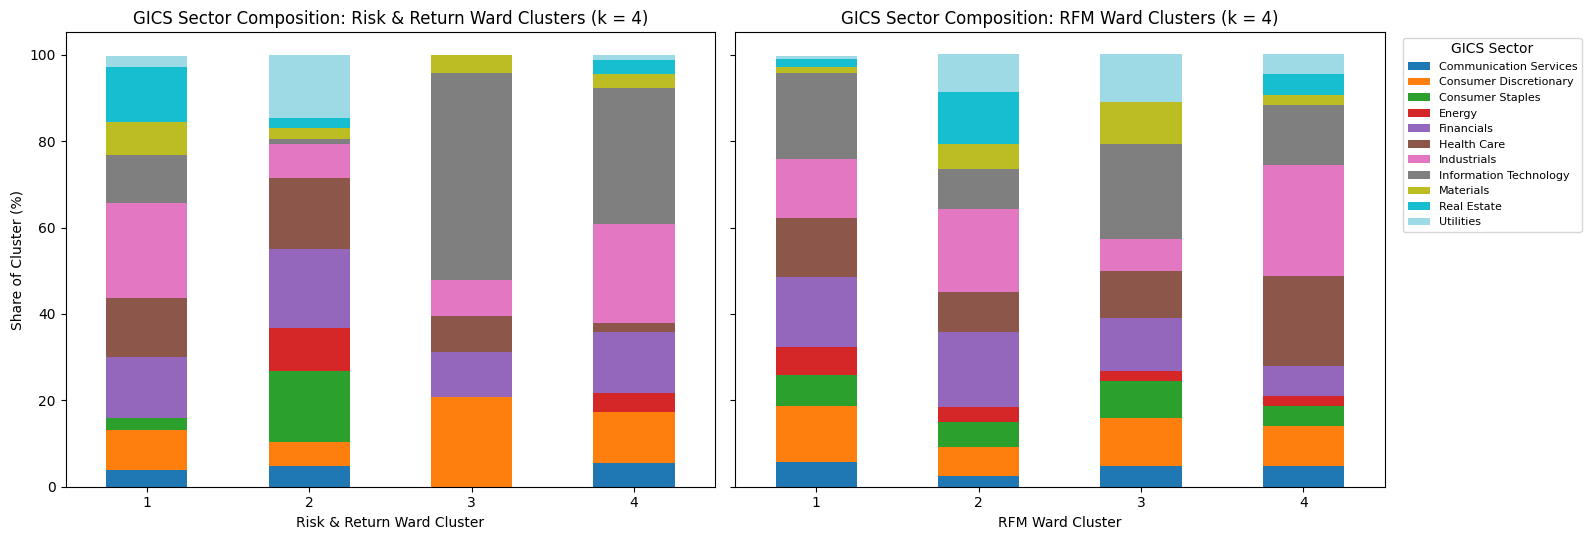


=== Task 3.2.3 Pairwise Weekly Return Correlation Evidence (n = 486 shares) ===
Overall mean pairwise return correlation:         0.2995
Mean correlation WITHIN same Risk-Return cluster: 0.3371
Mean correlation ACROSS diff Risk-Return clusters:0.2835
Cross-cluster pairs with correlation > 0.50:      6.27%


In [19]:
# Task 3.2 Supporting Evidence: GICS Sector composition & return dependency check
# 1. Sector composition (% within each cluster) for Ward Risk-Return and Ward RFM
rr_sector_ct = pd.crosstab(results_df['RR_Ward_Cluster'], results_df['GICS Sector'])
rfm_sector_ct = pd.crosstab(results_df['RFM_Ward_Cluster'], results_df['GICS Sector'])

rr_sector_pct = rr_sector_ct.div(rr_sector_ct.sum(axis=1), axis=0).mul(100).round(1)
rfm_sector_pct = rfm_sector_ct.div(rfm_sector_ct.sum(axis=1), axis=0).mul(100).round(1)

print('=== Task 3.2.1 Sector Composition (%): Ward Risk & Return Clusters ===')
display(rr_sector_pct)
print('\n=== Task 3.2.1 Sector Composition (%): Ward RFM Activity Clusters ===')
display(rfm_sector_pct)

print('\n=== Cross-Tab: Ward Risk & Return (rows) vs Ward RFM (columns) ===')
rr_vs_rfm_ct = pd.crosstab(results_df['RR_Ward_Cluster'], results_df['RFM_Ward_Cluster'], margins=True)
display(rr_vs_rfm_ct)

rr_sector_pct.to_csv(OUTPUT_DIR / 'task3_2_rr_sector_composition_pct.csv')
rfm_sector_pct.to_csv(OUTPUT_DIR / 'task3_2_rfm_sector_composition_pct.csv')
rr_vs_rfm_ct.to_csv(OUTPUT_DIR / 'task3_2_rr_vs_rfm_crosstab.csv')

# Plot side-by-side stacked bar charts of GICS Sector composition
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
rr_sector_pct.plot(kind='bar', stacked=True, colormap='tab20', ax=axes[0], legend=False)
axes[0].set_title('GICS Sector Composition: Risk & Return Ward Clusters (k = 4)')
axes[0].set_xlabel('Risk & Return Ward Cluster')
axes[0].set_ylabel('Share of Cluster (%)')
axes[0].tick_params(axis='x', rotation=0)

rfm_sector_pct.plot(kind='bar', stacked=True, colormap='tab20', ax=axes[1])
axes[1].set_title('GICS Sector Composition: RFM Ward Clusters (k = 4)')
axes[1].set_xlabel('RFM Ward Cluster')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='GICS Sector', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task3_2_1_sector_composition.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Task 3.2.3 Return dependency check: pairwise weekly return correlations
# Shows empirically why beta differences alone do not guarantee diversification
corr_mat = share_weekly_returns[results_df['Ticker']].corr().to_numpy()
rr_labels_arr = results_df['RR_Ward_Cluster'].to_numpy()
n_shares = len(rr_labels_arr)
tri_i, tri_j = np.triu_indices(n_shares, k=1)

same_cluster = rr_labels_arr[tri_i] == rr_labels_arr[tri_j]
pair_corrs = corr_mat[tri_i, tri_j]

print('\n=== Task 3.2.3 Pairwise Weekly Return Correlation Evidence (n = 486 shares) ===')
print(f'Overall mean pairwise return correlation:         {pair_corrs.mean():.4f}')
print(f'Mean correlation WITHIN same Risk-Return cluster: {pair_corrs[same_cluster].mean():.4f}')
print(f'Mean correlation ACROSS diff Risk-Return clusters:{pair_corrs[~same_cluster].mean():.4f}')
print(f'Cross-cluster pairs with correlation > 0.50:      {100 * (pair_corrs[~same_cluster] > 0.50).mean():.2f}%')

In [20]:
# Check all saved snapshots, output tables, and figures
print('=== Saved Data Snapshots ===')
for p in sorted(DATA_DIR.glob('*')):
    print(f'  {p.name} ({p.stat().st_size/1024:.1f} KB)')

print('\n=== Saved Output Tables ===')
for p in sorted(OUTPUT_DIR.glob('*')):
    print(f'  {p.name} ({p.stat().st_size/1024:.1f} KB)')

print('\n=== Saved Figures ===')
for p in sorted(FIG_DIR.glob('*')):
    print(f'  {p.name} ({p.stat().st_size/1024:.1f} KB)')

=== Saved Data Snapshots ===
  benchmark_gspc.csv (53.2 KB)
  daily_adj_close.csv (8821.5 KB)
  daily_close.csv (8634.6 KB)
  daily_dividends.csv (1967.8 KB)
  daily_splits.csv (1960.6 KB)
  daily_volume.csv (3843.7 KB)
  data_provenance.json (1.0 KB)
  sp500_tickers.csv (36.8 KB)

=== Saved Output Tables ===
  exclusion_log.csv (1.5 KB)
  master_feature_and_cluster_assignments.csv (94.7 KB)
  package_versions.csv (0.1 KB)
  profile_rf_only_ward_k4.csv (0.2 KB)
  profile_rfm_kmeans_k4.csv (0.2 KB)
  profile_rfm_ward_k4.csv (0.2 KB)
  profile_rr_kmeans_k4.csv (0.2 KB)
  profile_rr_ward_k4.csv (0.2 KB)
  task1_feature_summary.csv (0.7 KB)
  task1_feature_table.csv (71.1 KB)
  task2_2_ward_k_evaluation.csv (0.9 KB)
  task2_3_kmeans_k_evaluation.csv (1.0 KB)
  task2_4_rfm_pca_loadings.csv (0.1 KB)
  task2_5_1_rfm_pearson_corr.csv (0.1 KB)
  task2_5_1_rfm_spearman_corr.csv (0.1 KB)
  task2_5_2_monetary_removal_crosstab.csv (0.1 KB)
  task2_skew_outlier_diagnostics.csv (0.5 KB)
  task3_2_rfm